# Telco Customer Churn: Q4 Retention Campaign Targeting

**Business question (Head of Customer Retention):** Which customers should we target with a $100 retention credit to protect the most revenue, and is the campaign worth running at all?

- Capacity: up to 1,000 contacts. The offer keeps ~30% of genuine leavers; stayers still take the credit.
- Constraint: the model runs at the **start** of the quarter and can only use information available then.
- Deliverables: churn scores with drivers, recommended target list and size, expected financial outcome, 2–3 product insights.

**Training framing:** given what a customer looked like at the start of Q3 (1 July), did they leave during Q3?

### Headline results

- **Model:** logistic regression on 26 features known at the start of the quarter. Test AUC **0.899**: pick one leaver and one stayer at random, and the model ranks the leaver higher about 90% of the time.
- **Recommendation (6-month main case):** contact **253** customers. Expected revenue saved **\$30,410**, credit cost **\$25,300**, expected net **\$5,110**.
- **Sensitivity:** at 3 months no customer is worth contacting; at 12 months the optimal list is 883 customers with an expected net of \$61,179. The result depends heavily on how long saved customers stay.
- **Who the targets are:** 85% of the top 1,000 at rist customers in Q4 are on month-to-month contracts, vs 38% of all customers.

### Notebook structure

0. Setup · 1. Data preparation · 2. Data audit and feature selection · 3. Exploratory analysis · 4. Feature preparation · 5. Modelling (three iterations) · 6. Final model evaluation · 7. Business translation

## 0. Setup and imports

In [1]:
import pandas as pd
import numpy as np

# Visualisation
import matplotlib.pyplot as plt
import seaborn as sns

# Modelling
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score, root_mean_squared_error

# Evaluation
from sklearn.metrics import (roc_auc_score, roc_curve, precision_score, recall_score,
                             confusion_matrix, classification_report)

# Display settings: show all columns when printing DataFrames
pd.set_option('display.max_columns', None)

# 1. Data preparation

- Checked Customer ID is unique in every table.
- Merged Services + Status + Location + Demographics on Customer ID (inner joins), then Population on Zip Code.
- Result: `merge_final`, 7,043 rows, row count unchanged at every step, no duplicate `_x`/`_y` columns.
- Saved to `telco_merged.csv`.

## 1.1 Load the raw tables

In [2]:
df_demographics_data = pd.read_csv("Telco_customer_churn_demographics.csv")
df_churn_location_data = pd.read_csv("Telco_customer_churn_location.csv")
df_services_data = pd.read_csv("Telco_customer_churn_services.csv")
df_status_data = pd.read_csv("Telco_customer_churn_status.csv")
df_churn_population_data = pd.read_csv("Telco_customer_churn_population.csv")

## 1.2 Check Customer ID / Zip Code uniqueness and row counts

In [3]:
print(df_services_data['Customer ID'].is_unique)
len(df_services_data)

True


7043

In [4]:
print(df_status_data['Customer ID'].is_unique)
len(df_status_data)

True


7043

In [5]:
print(df_demographics_data['Customer ID'].is_unique)
len(df_demographics_data)

True


7043

In [6]:
print(df_churn_location_data['Customer ID'].is_unique)
len(df_churn_location_data)

True


7043

In [7]:
print(df_churn_population_data['Zip Code'].is_unique)
len(df_churn_population_data)

True


1671

## 1.3 Merge the tables

In [8]:
merge1 = pd.merge(df_services_data, df_status_data.drop(columns=['Count', 'Quarter']), how="inner", on="Customer ID")

In [9]:
merge2 = pd.merge(merge1, df_churn_location_data.drop(columns='Count'), how="inner", on="Customer ID")

In [10]:
merge3 = pd.merge(merge2, df_demographics_data.drop(columns='Count'), how="inner", on="Customer ID")

In [11]:
merge_final = pd.merge(merge3, df_churn_population_data.drop(columns='ID'), how="inner", on="Zip Code")

In [12]:
merge_final = merge_final.drop(columns='Count')

In [13]:
merge_final.columns

Index(['Customer ID', 'Quarter', 'Referred a Friend', 'Number of Referrals',
       'Tenure in Months', 'Offer', 'Phone Service',
       'Avg Monthly Long Distance Charges', 'Multiple Lines',
       'Internet Service', 'Internet Type', 'Avg Monthly GB Download',
       'Online Security', 'Online Backup', 'Device Protection Plan',
       'Premium Tech Support', 'Streaming TV', 'Streaming Movies',
       'Streaming Music', 'Unlimited Data', 'Contract', 'Paperless Billing',
       'Payment Method', 'Monthly Charge', 'Total Charges', 'Total Refunds',
       'Total Extra Data Charges', 'Total Long Distance Charges',
       'Total Revenue', 'Satisfaction Score', 'Customer Status', 'Churn Label',
       'Churn Value', 'Churn Score', 'CLTV', 'Churn Category', 'Churn Reason',
       'Country', 'State', 'City', 'Zip Code', 'Lat Long', 'Latitude',
       'Longitude', 'Gender', 'Age', 'Under 30', 'Senior Citizen', 'Married',
       'Dependents', 'Number of Dependents', 'Population'],
      dtype='

## 1.4 Save the merged dataset

In [14]:
merge_final.to_csv('telco_merged.csv', index=False)

## 1.5 Define the active population (exclude Joined) and create the tenure groups

In [15]:
# Customers at the start of the quarter only. We will use this dataframe moving forward as part of the data audit and EDA.
active = merge_final[merge_final['Customer Status'] != 'Joined'].copy()

In [16]:
active['Tenure Group'] = pd.cut(active['Tenure in Months'],
                                bins=[0, 6, 12, 24, 48, 72],
                                labels=['0-6', '7-12', '13-24', '25-48', '49-72'])

# 2. Data audit and feature selection

Each column that could be a potential feature is reviewed and passed through multiple stage gates:

1. Availability: would we know this value on the 1st of Q4, before anyone churns?
2. Leakage: is the column's value a *cause / background fact* of churning, or a *consequence* of it?
Red flags: a category with 0% or 100% churn; a column blank for only one group; a model that suddenly becomes near-perfect.
3. Redundancy: Is the feature a copy of other features already in the dataset?
4. Signal: Does churn rate differ across its values, and does that survive holding across other strong churn indicator features.
5. Practicality: Can the model use it sensibly and can you explain it?

## 2.1 Baseline churn rate (all customers vs excluding Joined)

In [17]:
merge_final['Churn Value'].mean()

np.float64(0.2653698707936959)

In [18]:
active['Churn Value'].mean()

np.float64(0.2836545758081651)

Baseline churn rate of starting population in Q3 is 28.4%

## 2.2 Customer Status vs Churn Label

In [19]:
# Create a cross-tabulation of customer status vs churn label. Trying to see if there's overlap or a direct link which would clarify leakiness...
result = pd.crosstab(df_status_data['Customer Status'], df_status_data['Churn Label'])
print(result)

Churn Label        No   Yes
Customer Status            
Churned             0  1869
Joined            454     0
Stayed           4720     0


Customer Status vs Churn Label: no overlap. All 454 “Joined” customers have Churn Label = No, so new customers who joined and then left during Q3 are recorded as “Churned”, not “Joined”. The “Joined” group therefore only contains new customers who stayed to the end of the quarter.

Decision: exclude the 454 Joined customers from training. Two reasons:

They weren’t customers on 1 July, so they don’t fit the training question: “given a customer at the start of Q3, did they leave during Q3?”
Keeping them would add 454 new customers who never churn, which would understate how risky new customers are (in reality, ~78% of customers in their first 6 months left).

## 2.3 Satisfaction Score vs Churn Label

In [20]:
# Create a cross-tabulation of satisfaction score vs churn label. Trying to see if there's overlap or a direct link which would clarify leakiness... this is because 
satisfaction_score_churn = pd.crosstab(active['Satisfaction Score'], active['Churn Label'])
print(satisfaction_score_churn)

Churn Label           No  Yes
Satisfaction Score           
1                      0  922
2                      0  518
3                   2079  429
4                   1637    0
5                   1004    0


This column behaves like the outcome of churning / staying, not like a predictor of it. Also, we can't rely on having a score like this for every customer on 1 October. So, we rule out using this feature in our training model. The results strongly suggest that this survey is taken at or after the point people left, like an exist survey.

## 2.4 Offer: churn by offer, holding tenure constant

In [21]:
active['Offer'].value_counts(dropna=False)

Offer
NaN        3598
Offer B     824
Offer E     630
Offer D     602
Offer A     520
Offer C     415
Name: count, dtype: int64

In [22]:
active['Offer'] = active['Offer'].fillna('None')

In [23]:
offer_churn_rate = pd.crosstab(active['Offer'], active['Churn Label'], normalize='index')
print((offer_churn_rate * 100).round(1))

Churn Label    No   Yes
Offer                  
None         70.8  29.2
Offer A      93.3   6.7
Offer B      87.7  12.3
Offer C      77.1  22.9
Offer D      73.3  26.7
Offer E      32.4  67.6


In [24]:
active.groupby('Offer')['Tenure in Months'].mean()

Offer
None       33.880211
Offer A    70.000000
Offer B    53.358010
Offer C    30.761446
Offer D    15.951827
Offer E     4.257143
Name: Tenure in Months, dtype: float64

In [25]:
pd.crosstab(active['Offer'], active['Tenure Group'], values=active['Churn Label'], aggfunc='count').round(3)

Tenure Group,0-6,7-12,13-24,25-48,49-72
Offer,,,,,
None,556,385,548,971,1138
Offer A,0,0,0,0,520
Offer B,0,0,0,243,581
Offer C,0,0,35,380,0
Offer D,0,161,441,0,0
Offer E,460,170,0,0,0


In [26]:
pd.crosstab(active['Offer'], active['Tenure Group'], values=active['Churn Value'], aggfunc='mean').round(3)

Tenure Group,0-6,7-12,13-24,25-48,49-72
Offer,,,,,
None,0.750,0.382,0.314,0.207,0.100
Offer A,NaN,NaN,NaN,NaN,0.067
Offer B,NaN,NaN,NaN,0.152,0.110
Offer C,NaN,NaN,0.229,0.229,NaN
Offer D,NaN,0.292,0.259,NaN,NaN
Offer E,0.798,0.347,NaN,NaN,NaN


Decision on the column 'offer': Drop it

Gate 4 (signal) is weak. Once you hold tenure constant, the 26-point raw gap shrinks to a few points and flips direction. The model would therefore learn very little from it, holding other features constant.

It's close to a copy of tenure (Gate 3). Each offer only exists in fixed tenure bands. If I tell you a customer has Offer A, you already know they've been with us 49–72 months. Tenure is already in the model, and Offer mostly repeats it.

It carries Gate 1/2 risk. The field is the last offer accepted. If some customers accepted it during Q3, especially as a "please stay" offer, we wouldn't have known it on 1 July. In that case it's partly a consequence of being at risk.

Gate 5 (practicality). It's six categories for the stakeholder to understand, for almost no gain. 

## 2.5 Totals columns: cause or consequence?

Checks to do: is Total Charges redundant with Tenure × Monthly Charge? Is Total Revenue the sum of the other totals?

### 2.5.1 Total Charges and Total Revenue

In [27]:
# Check 1: is Total Charges just tenure x monthly charge?
active['Tenure x Monthly'] = active['Tenure in Months'] * active['Monthly Charge']
print(active[['Tenure x Monthly', 'Total Charges']].corr())

# Check 2: does Total Revenue reconstruct exactly?
rebuilt = (active['Total Charges'] - active['Total Refunds']
           + active['Total Extra Data Charges']
           + active['Total Long Distance Charges'])
print((rebuilt - active['Total Revenue']).abs().max())

                  Tenure x Monthly  Total Charges
Tenure x Monthly           1.00000        0.99953
Total Charges              0.99953        1.00000
1.8189894035458565e-12


Total Charges: dropped. Near-duplicate of tenure × monthly charge (r = 0.9995), so it adds no information, inherits tenure's truncation leakage, and would make coefficients unstable.

Total Revenue: dropped. Exactly equals Total Charges − Total Refunds + Total Extra Data + Total Long Distance (max difference 1.8e-12), so it adds no information and inherits the tenure leakage of its components.

### 2.5.2 Total Refunds

In [28]:
active['Has Refund'] = active['Total Refunds'] > 0

# How many customers have any refund at all?
print(active['Has Refund'].value_counts())

# Churn rate with vs without a refund
print(pd.crosstab(active['Has Refund'], active['Churn Label'], normalize='index'))

Has Refund
False    6069
True      520
Name: count, dtype: int64
Churn Label        No       Yes
Has Refund                     
False        0.709672  0.290328
True         0.794231  0.205769


In [29]:
# Churn rate by tenure group, with vs without refund
print(pd.crosstab(active['Tenure Group'], active['Has Refund'],
                  values=active['Churn Value'], aggfunc='mean').round(3))

# Counts, so you can spot small cells
print(pd.crosstab(active['Tenure Group'], active['Has Refund']))

Has Refund    False  True 
Tenure Group              
0-6           0.773  0.696
7-12          0.347  0.438
13-24         0.292  0.239
25-48         0.205  0.190
49-72         0.096  0.090
Has Refund    False  True 
Tenure Group              
0-6             993     23
7-12            668     48
13-24           932     92
25-48          1436    158
49-72          2040    199


The no-refund group’s 29% is inflated because it contains most of the brand-new customers, who churn at ~70–77% whether or not they had a refund. Compare within the same tenure band and the “refund effect” mostly disappears.

Total Refunds: dropped. Not leaky (refund-holders churn less, not more), but no independent signal: within tenure groups the gap shrinks to 0.6–5 pts and reverses at 7–12 months; the raw gap (29% vs 20.6%) is driven by refund-holders being longer-tenure customers.

### 2.5.3 Total Long Distance Charges

In [30]:
active['Tenure x Avg LD'] = active['Tenure in Months'] * active['Avg Monthly Long Distance Charges']
print(active[['Tenure x Avg LD', 'Total Long Distance Charges']].corr())

                             Tenure x Avg LD  Total Long Distance Charges
Tenure x Avg LD                          1.0                          1.0
Total Long Distance Charges              1.0                          1.0


Total Long Distance Charges: dropped. Exactly tenure × Avg Monthly Long Distance (r = 1.00), so it adds no information, and as a running total it inherits tenure's truncation leakage.

### 2.5.4 Total Extra Data Charges

In [31]:
capped = active[(active['Internet Service'] == 'Yes') &
                (active['Unlimited Data'] == 'No')].copy()

capped['Has Extra Data'] = capped['Total Extra Data Charges'] > 0

# How many can be charged, and how many were?
print(len(capped))
print(capped['Has Extra Data'].value_counts())

# Raw churn rate with vs without extra data charges
print(capped.groupby('Has Extra Data')['Churn Value'].agg(['mean', 'count']).round(3))

# Holding tenure constant (Tenure Group already exists on active, so it's carried over)
print(pd.crosstab(capped['Tenure Group'], capped['Has Extra Data'],
                  values=capped['Churn Value'], aggfunc='mean').round(3))
print(pd.crosstab(capped['Tenure Group'], capped['Has Extra Data']))

724
Has Extra Data
True     684
False     40
Name: count, dtype: int64
                 mean  count
Has Extra Data              
False           0.375     40
True            0.349    684
Has Extra Data  False  True 
Tenure Group                
0-6             0.667  0.814
7-12            0.571  0.507
13-24           0.333  0.356
25-48           0.333  0.279
49-72           0.111  0.149
Has Extra Data  False  True 
Tenure Group                
0-6                 6    102
7-12                7     71
13-24               6    104
25-48              12    172
49-72               9    235


Total extra data charges: decision to drop. Reasons:

Running total → tenure leak. Like the other "Total" columns, it's time × intensity, so it inherits tenure's truncation problem.

"Has charges" is almost the same as being a capped internet customer. 684 of 724 (94%) have extra charges, so it mostly repeats Internet Service + Unlimited Data, which are already in the model.

Usage is already captured per month by Avg Monthly GB Download, so we don't need the total version.

No consistent churn gap within tenure groups. Raw churn is 34.9% vs 37.5%, and only 40 customers have no charges, which is too few to trust.

## 2.6 Avg Monthly Long Distance Charges

In [32]:
print(active[['Monthly Charge', 'Avg Monthly Long Distance Charges']].corr())

                                   Monthly Charge  \
Monthly Charge                           1.000000   
Avg Monthly Long Distance Charges        0.140487   

                                   Avg Monthly Long Distance Charges  
Monthly Charge                                              0.140487  
Avg Monthly Long Distance Charges                           1.000000  


Avg monthly long distance charge has a very weak correlation with monthly charge, which suggests that they measure separate information. Monthly charge isn't 'built up' from monthly long distance charges, and are 2 separate things - so it's worth considering if it impacts churn rate signficantly before including it in our model.

In [33]:
phone = active[active['Phone Service'] == 'Yes'].copy()

# Split Avg LD into 4 equal-sized groups (quartiles)
phone['LD Band'] = pd.qcut(phone['Avg Monthly Long Distance Charges'], q=4)

# Raw churn rate by LD band
print(phone.groupby('LD Band')['Churn Value'].agg(['mean', 'count']).round(3))

# Holding contract constant
print(pd.crosstab(phone['LD Band'], phone['Contract'],
                  values=phone['Churn Value'], aggfunc='mean').round(3))

                              mean  count
LD Band                                  
(1.0090000000000001, 13.14]  0.290   1487
(13.14, 25.72]               0.278   1487
(25.72, 37.69]               0.291   1486
(37.69, 49.99]               0.284   1485
Contract                     Month-to-Month  One Year  Two Year
LD Band                                                        
(1.0090000000000001, 13.14]           0.525     0.116     0.021
(13.14, 25.72]                        0.518     0.109     0.020
(25.72, 37.69]                        0.530     0.111     0.035
(37.69, 49.99]                        0.508     0.106     0.033


/var/folders/bc/3dcn_n7n57vc2b1xf81g4zhr0000gn/T/ipykernel_58924/454560987.py:7: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  print(phone.groupby('LD Band')['Churn Value'].agg(['mean', 'count']).round(3))


Avg Monthly Long Distance Charges: dropped.

Reason: Among phone customers, churn is flat across LD quartiles both overall (27.8–29.1%) and within each contract type (MTM 51–53%, one-year 11–12%, two-year 2–3.5%), so it adds no predictive signal and would only clutter the model.

## 2.7 Internet Service vs Internet Type

In [34]:
pd.crosstab(active['Internet Service'], active['Internet Type'].fillna('None'))

Internet Type,Cable,DSL,Fiber Optic,None
Internet Service,,,,
No,0,0,0,1344
Yes,774,1537,2934,0


Internet Service: dropped. Reason: crosstab of Internet Service × Internet Type → every "No" has Internet Type = None and every "Yes" has DSL/Fiber/Cable, so it can be rebuilt exactly from Internet Type, which carries more detail → keep Internet Type (blanks filled as 'None'), drop Internet Service.

## 2.8 Avg Monthly GB Download

In [35]:
net = active[active['Internet Service'] == 'Yes'].copy()
net.groupby('Internet Type')['Avg Monthly GB Download'].agg(['mean', 'min', 'max', 'count']).round(1)

,mean,min,max,count
Internet Type,,,,
Cable,27.9,2,85,774
DSL,27.5,2,85,1537
Fiber Optic,25.1,2,85,2934


In [36]:
net['GB Quartile'] = pd.qcut(net['Avg Monthly GB Download'], 4, duplicates='drop')
net.groupby(['Contract', 'GB Quartile'], observed=True)['Churn Value'].agg(['mean', 'count']).round(3)

mean  count
Contract       GB Quartile                
Month-to-Month (1.999, 13.0]  0.616    816
               (13.0, 21.0]   0.534    639
               (21.0, 30.0]   0.585    792
               (30.0, 85.0]   0.416    599
One Year       (1.999, 13.0]  0.158    323
               (13.0, 21.0]   0.142    282
               (21.0, 30.0]   0.106    292
               (30.0, 85.0]   0.126    278
Two Year       (1.999, 13.0]  0.047    317
               (13.0, 21.0]   0.020    297
               (21.0, 30.0]   0.041    341
               (30.0, 85.0]   0.030    269

**Avg Monthly GB Download: keep.**

- **Not a copy of Internet Type:** average usage is almost the same for every connection type (25–28 GB, range 2–85 GB for all three), so it adds new information.
- **Real signal:** among month-to-month customers, the heaviest users (top quarter, 30+ GB) churn at 41.6%, vs 61.6% for the lightest users. For one-year contracts the drop is much smaller (3–5 points).
- **Small timing risk:** it's an average that may include some Q3 usage, but one quarter shouldn't move a long-run average much.

## 2.9 Phone Service and Multiple Lines

In [37]:
pd.crosstab(active['Phone Service'], active['Multiple Lines'])

Multiple Lines,No,Yes
Phone Service,,
No,644,0
Yes,3019,2926


In [38]:
phone = active[active['Phone Service'] == 'Yes'].copy()
phone.groupby(['Contract', 'Multiple Lines'])['Churn Value'].agg(['mean', 'count']).round(3)

mean  count
Contract       Multiple Lines              
Month-to-Month No              0.494   1580
               Yes             0.552   1307
One Year       No              0.081    728
               Yes             0.143    649
Two Year       No              0.014    711
               Yes             0.036    970

Phone Service + Multiple Lines: combined into Phone Lines (None / Single / Multiple).

Reason: crosstab Phone Service × Multiple Lines → all 644 non-phone customers show Multiple Lines = "No", so "No" mixes no phone with one line and neither column can be rebuilt from the other → combined into a single three-level column for clarity.

## 2.10 Number of Referrals vs Referred a Friend

In [39]:
# Raw: churn rate by number of referrals
print(active.groupby('Number of Referrals')['Churn Value'].agg(['mean', 'count']).round(3))

# Within tenure groups, plus counts
print(pd.crosstab(active['Number of Referrals'], active['Tenure Group'],
                  values=active['Churn Value'], aggfunc='mean').round(3))
print(pd.crosstab(active['Number of Referrals'], active['Tenure Group']))

                      mean  count
Number of Referrals              
0                    0.361   3448
1                    0.473   1071
2                    0.114    229
3                    0.130    247
4                    0.077    233
5                    0.082    255
6                    0.037    214
7                    0.025    243
8                    0.010    206
9                    0.018    226
10                   0.000    215
11                   0.000      2
Tenure Group           0-6   7-12  13-24  25-48  49-72
Number of Referrals                                   
0                    0.790  0.368  0.293  0.207  0.114
1                    0.848  0.667  0.566  0.485  0.249
2                    0.500  0.238  0.154  0.096  0.073
3                    0.588  0.158  0.161  0.148  0.042
4                    0.692  0.067  0.083  0.054  0.024
5                    0.600  0.231  0.091  0.071  0.035
6                    0.500  0.067  0.029  0.017  0.039
7                    0.000  0

In [40]:
# Raw: churn rate by 'referred a friend'
print(active.groupby('Referred a Friend')['Churn Value'].agg(['mean', 'count']).round(3))

# Within tenure groups, plus counts
print(pd.crosstab(active['Referred a Friend'], active['Tenure Group'],
                  values=active['Churn Value'], aggfunc='mean').round(3))
print(pd.crosstab(active['Referred a Friend'], active['Tenure Group']))

                    mean  count
Referred a Friend              
No                 0.361   3448
Yes                0.199   3141
Tenure Group        0-6   7-12  13-24  25-48  49-72
Referred a Friend                                  
No                 0.79  0.368  0.293  0.207  0.114
Yes                0.70  0.323  0.279  0.201  0.086
Tenure Group       0-6  7-12  13-24  25-48  49-72
Referred a Friend                                
No                 806   481    604    823    734
Yes                210   235    420    771   1505


**Referred a Friend: dropped. Number of Referrals: kept as bands (0 / 1 / 2–4 / 5+) for testing.**

- **Referred a Friend is redundant:** it's just "Number of Referrals > 0" (identical counts: 3,448 with none).
- **Yes/no hides the pattern:** customers with 1 referral churn about twice as much as those with 0 (e.g. 24.9% vs 11.4% at 49–72 months tenure), while 2+ referrals churn much less (2.4–7.3%). Bands keep both effects.
- **Risk:** the referral count may include referrals made during Q3, and the 1-referral spike has no obvious explanation (possible leakage, or a quirk of the generated data).
- **Outcome:** tested in model 1, where 1 referral had ~3x the odds of churning. With no business explanation for this and a possible timing problem, Referral Band was **dropped in model 2** (AUC 0.923 → 0.901).

## 2.11 Age, Under 30 and Senior Citizen

In [41]:
active['Age Band'] = pd.cut(active['Age'], bins=[0, 29, 44, 64, 120],
                            labels=['<30', '30-44', '45-64', '65+'])
active.groupby(['Tenure Group', 'Age Band'], observed=True)['Churn Value'].agg(['mean', 'count']).round(3)

mean  count
Tenure Group Age Band              
0-6          <30       0.716    201
             30-44     0.762    277
             45-64     0.772    351
             65+       0.845    187
7-12         <30       0.216    139
             30-44     0.367    210
             45-64     0.330    264
             65+       0.573    103
13-24        <30       0.220    205
             30-44     0.278    263
             45-64     0.240    388
             65+       0.494    168
25-48        <30       0.150    313
             30-44     0.145    420
             45-64     0.174    580
             65+       0.413    281
49-72        <30       0.086    444
             30-44     0.086    619
             45-64     0.077    803
             65+       0.161    373

Age: kept as Senior Citizen (Yes/No); Age, Under 30 and Age Band dropped. 

Reason: churn by age band within tenure groups → bands under 65 are similar (e.g. 14.5–17.4% at 25–48 months) with no consistent order, while 65+ is roughly double from 7 months onwards (e.g. 41.3% at 25–48, n = 281) → the effect is a single step at 65, captured fully by Senior Citizen. Under 30 adds no consistent signal.

## 2.12 Dependents and Number of Dependents

In [42]:
active.groupby('Dependents')['Churn Value'].agg(['mean', 'count'])

,mean,count
Dependents,,
No,0.349663,5042
Yes,0.068520,1547


In [43]:
active.groupby('Number of Dependents')['Churn Value'].agg(['mean', 'count'])

,mean,count
Number of Dependents,,
0,0.349663,5042
1,0.072243,526
2,0.065217,506
3,0.061100,491
4,0.125000,8
5,0.222222,9
6,0.333333,3
7,0.500000,2
8,0.000000,1


Decision to keep Dependents (y/n) as added number of dependents beyond 1 gives no extra signal on churn rate. From 4 onwards, sample sizes are too small, and there is almost no difference in churn rate between 1 to 3 dependents (between 0.072 and 0.061). 

## 2.13 Columns excluded from the model

- **Satisfaction Score, Customer Status, Churn Reason, Churn Score:** recorded at or after the point of leaving (consequences of churn, not causes).
- **CLTV:** not used for ranking; Monthly Charge is used as the revenue figure instead.
- **Gender, location columns (Zip Code, Latitude, Longitude, City), Population, Number of Services:** not included in this version. 
- **Referral Band and Monthly Charge** passed the audit but were removed during modelling (see Section 5).

# 3. Exploratory analysis

- Check for any outliers / na's
- Churn rate by the features kept, charges vs churn, the range of Monthly Charge.
- Output: charts and draft product-team insights.

## 3.1 Overview of the merged data

In [44]:
active.columns

Index(['Customer ID', 'Quarter', 'Referred a Friend', 'Number of Referrals',
       'Tenure in Months', 'Offer', 'Phone Service',
       'Avg Monthly Long Distance Charges', 'Multiple Lines',
       'Internet Service', 'Internet Type', 'Avg Monthly GB Download',
       'Online Security', 'Online Backup', 'Device Protection Plan',
       'Premium Tech Support', 'Streaming TV', 'Streaming Movies',
       'Streaming Music', 'Unlimited Data', 'Contract', 'Paperless Billing',
       'Payment Method', 'Monthly Charge', 'Total Charges', 'Total Refunds',
       'Total Extra Data Charges', 'Total Long Distance Charges',
       'Total Revenue', 'Satisfaction Score', 'Customer Status', 'Churn Label',
       'Churn Value', 'Churn Score', 'CLTV', 'Churn Category', 'Churn Reason',
       'Country', 'State', 'City', 'Zip Code', 'Lat Long', 'Latitude',
       'Longitude', 'Gender', 'Age', 'Under 30', 'Senior Citizen', 'Married',
       'Dependents', 'Number of Dependents', 'Population', 'Tenure Group'

In [45]:
active.describe()

,Number of Referrals,Tenure in Months,Avg Monthly Long Distance Charges,Avg Monthly GB Download,Monthly Charge,Total Charges,Total Refunds,Total Extra Data Charges,Total Long Distance Charges,Total Revenue,Satisfaction Score,Churn Value,Churn Score,CLTV,Zip Code,Latitude,Longitude,Age,Number of Dependents,Tenure x Monthly,Tenure x Avg LD
count,6589.000000,6589.000000,6589.000000,6589.000000,6589.000000,6589.000000,6589.000000,6589.000000,6589.000000,6589.000000,6589.000000,6589.000000,6589.000000,6589.000000,6589.000000,6589.000000,6589.000000,6589.000000,6589.000000,6589.000000,6589.000000
mean,2.020944,34.499772,23.004277,20.876461,66.228472,2432.042243,2.080938,7.169525,798.087251,3235.218082,3.194718,0.283655,59.191228,4422.180756,93491.504477,36.199761,-119.757670,46.760510,0.476097,2431.872492,798.087251
std,3.024016,23.968734,15.466844,20.406247,29.907382,2265.500080,8.125054,25.803163,853.767972,2854.600036,1.207720,0.450805,21.231782,1179.656518,1857.575392,2.472459,2.155696,16.841362,0.968499,2263.308078,853.767972
min,0.000000,1.000000,0.000000,0.000000,18.250000,18.850000,0.000000,0.000000,0.000000,21.610000,1.000000,0.000000,5.000000,2003.000000,90001.000000,32.555828,-124.301372,19.000000,0.000000,18.850000,0.000000
25%,0.000000,12.000000,9.250000,4.000000,40.550000,544.550000,0.000000,0.000000,106.680000,835.450000,3.000000,0.000000,41.000000,3513.000000,92103.000000,33.989524,-121.788090,33.000000,0.000000,545.000000,106.680000
50%,0.000000,32.000000,22.920000,17.000000,72.850000,1563.900000,0.000000,0.000000,472.680000,2376.450000,3.000000,0.000000,63.000000,4552.000000,93526.000000,36.245926,-119.601370,46.000000,0.000000,1561.450000,472.680000
75%,3.000000,57.000000,36.440000,27.000000,90.600000,4003.000000,0.000000,0.000000,1275.120000,5106.640000,4.000000,1.000000,76.000000,5393.000000,95333.000000,38.169605,-117.967399,60.000000,0.000000,3992.650000,1275.120000
max,11.000000,72.000000,49.990000,85.000000,118.750000,8684.800000,49.790000,150.000000,3564.720000,11979.340000,5.000000,1.000000,96.000000,6500.000000,96150.000000,41.962127,-114.192901,80.000000,9.000000,8550.000000,3564.720000


## 3.2 Distributions of numeric columns

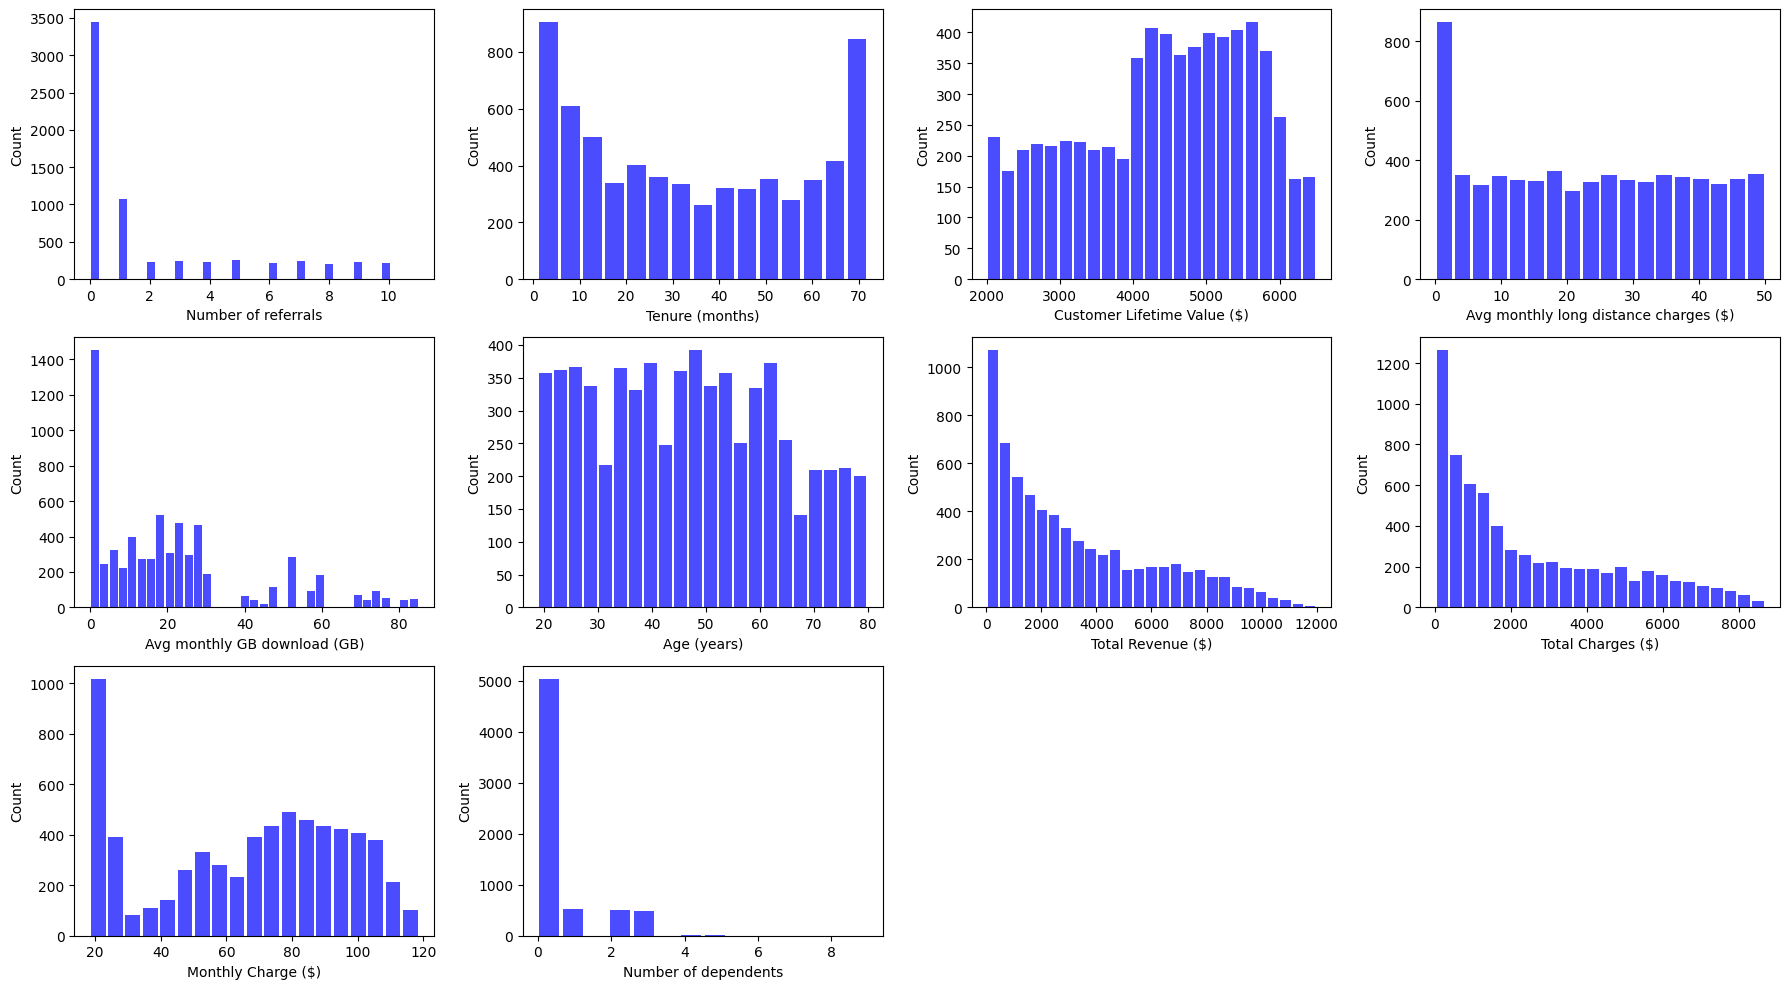

In [46]:
cols = ['Number of Referrals', 'Tenure in Months', 'CLTV',
        'Avg Monthly Long Distance Charges', 'Avg Monthly GB Download', 'Age',
        'Total Revenue', 'Total Charges', 'Monthly Charge', 'Number of Dependents']

labels = ['Number of referrals', 'Tenure (months)', 'Customer Lifetime Value ($)',
          'Avg monthly long distance charges ($)', 'Avg monthly GB download (GB)', 'Age (years)',
          'Total Revenue ($)', 'Total Charges ($)', 'Monthly Charge ($)', 'Number of dependents']

fig, axes = plt.subplots(3, 4, figsize=(18, 10))   # 12 panels for 10 charts
axes = axes.flatten()

for i, col in enumerate(cols):
    axes[i].hist(active[col], bins='auto', color='blue', alpha=0.7, rwidth=0.85)
    axes[i].set_xlabel(labels[i])
    axes[i].set_ylabel('Count')

for ax in axes[len(cols):]:   # hide the 2 empty panels
    ax.set_visible(False)

plt.tight_layout()
plt.show()

It doesn't look like there are any obvious outliers from the distributions of the numeric columns.

In [47]:
active.isna().sum()

Customer ID                             0
Quarter                                 0
Referred a Friend                       0
Number of Referrals                     0
Tenure in Months                        0
Offer                                   0
Phone Service                           0
Avg Monthly Long Distance Charges       0
Multiple Lines                          0
Internet Service                        0
Internet Type                        1344
Avg Monthly GB Download                 0
Online Security                         0
Online Backup                           0
Device Protection Plan                  0
Premium Tech Support                    0
Streaming TV                            0
Streaming Movies                        0
Streaming Music                         0
Unlimited Data                          0
Contract                                0
Paperless Billing                       0
Payment Method                          0
Monthly Charge                    

Internet Type has 1344 NA's but these are meant to mean 'No Internet Service', so we will replace these with 'none' before building the model.

## 3.3 Financial impact of churn

In [48]:
total_monthly_charges = active['Monthly Charge'].sum()
total_monthly_charges_churners = active[active['Churn Label'] == 'Yes']['Monthly Charge'].sum()
monthly_charges_proportion_churners = total_monthly_charges_churners / total_monthly_charges

print(f"Total monthly revenue, all customers active on 1 July: ${total_monthly_charges:,.2f}")
print(f"Monthly revenue from customers who left in Q3:          ${total_monthly_charges_churners:,.2f}")
print(f"Share of monthly revenue lost to churn:                  {monthly_charges_proportion_churners:.1%}")

Total monthly revenue, all customers active on 1 July: $436,379.40
Monthly revenue from customers who left in Q3:          $139,130.85
Share of monthly revenue lost to churn:                  31.9%


In [49]:
active['Churn Label'].value_counts()

Churn Label
No     4720
Yes    1869
Name: count, dtype: int64

In [50]:
churners = merge_final[merge_final['Customer Status'] == 'Churned']
avg_charge_churners = churners['Monthly Charge'].mean()
print(f'Average monthly charge, churners: ${avg_charge_churners:.2f}')

Average monthly charge, churners: $74.44


In [51]:
merge_final['Customer Status'].value_counts()

Customer Status
Stayed     4720
Churned    1869
Joined      454
Name: count, dtype: int64

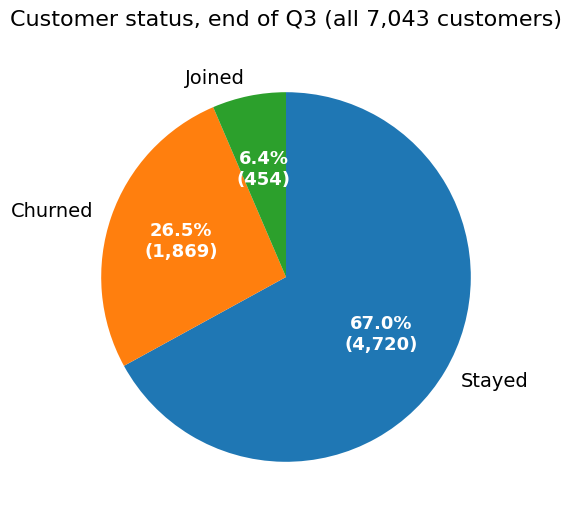

In [52]:
status_counts = merge_final['Customer Status'].value_counts()
total = status_counts.sum()

def make_label(pct):
    count = round(pct / 100 * total)
    return f'{pct:.1f}%\n({count:,})'

fig, ax = plt.subplots(figsize=(6, 6))

wedges, outer_labels, inner_labels = ax.pie(
    status_counts,
    labels=status_counts.index,
    autopct=make_label,
    startangle=90,
    counterclock=False,
    textprops={'fontsize': 14},
)

for label in inner_labels:
    label.set_fontsize(13)
    label.set_color('white')
    label.set_fontweight('bold')

ax.set_title(f'Customer status, end of Q3 (all {total:,} customers)',
             fontsize=16, pad=15)

fig.savefig('q3_customer_status_pie.png', dpi=200, bbox_inches='tight')
plt.show()

## 3.4 Tenure and charges vs churn

<Axes: title={'center': 'Tenure in Months'}, xlabel='Churn Label'>

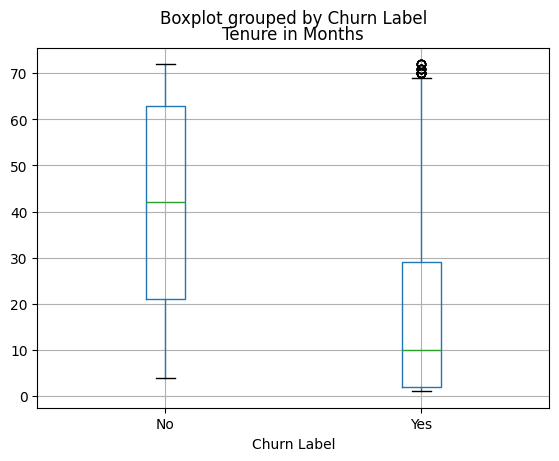

In [53]:
active.boxplot(column='Tenure in Months', by='Churn Label')

In [54]:
active.groupby('Churn Label')['Tenure in Months'].agg('median')

Churn Label
No     42.0
Yes    10.0
Name: Tenure in Months, dtype: float64

<Axes: title={'center': 'Monthly Charge'}, xlabel='Churn Label'>

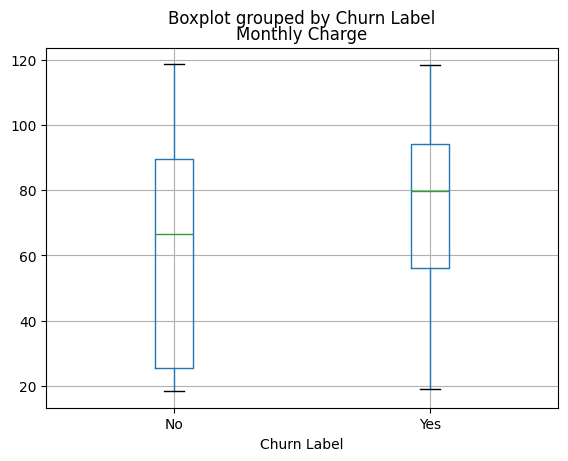

In [55]:
active.boxplot(column='Monthly Charge', by='Churn Label')

In [56]:
active.groupby('Churn Label')['Monthly Charge'].agg('mean')

Churn Label
No     62.976388
Yes    74.441332
Name: Monthly Charge, dtype: float64

<Axes: title={'center': 'Total Charges'}, xlabel='Churn Label'>

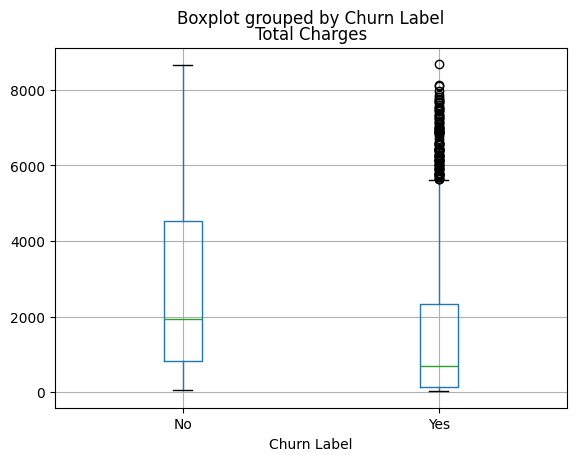

In [57]:
active.boxplot(column='Total Charges', by='Churn Label')

In [58]:
active['Charge Band'] = pd.qcut(active['Monthly Charge'], 5)
active.groupby(['Contract', 'Charge Band'], observed=True)['Churn Value'].agg(['mean', 'count']).round(3)

mean  count
Contract       Charge Band                  
Month-to-Month (18.249, 25.45]  0.323    399
               (25.45, 60.81]   0.437    749
               (60.81, 79.99]   0.571    756
               (79.99, 94.8]    0.584    770
               (94.8, 118.75]   0.600    528
One Year       (18.249, 25.45]  0.029    342
               (25.45, 60.81]   0.076    302
               (60.81, 79.99]   0.084    273
               (79.99, 94.8]    0.114    228
               (94.8, 118.75]   0.220    381
Two Year       (18.249, 25.45]  0.009    585
               (25.45, 60.81]   0.019    259
               (60.81, 79.99]   0.017    288
               (79.99, 94.8]    0.019    323
               (94.8, 118.75]   0.067    406

,Churn rate (%),Customers
Monthly bill,,
$18–25,32.3,399
$25–61,43.7,749
$61–80,57.1,756
$80–95,58.4,770
$95–119,60.0,528


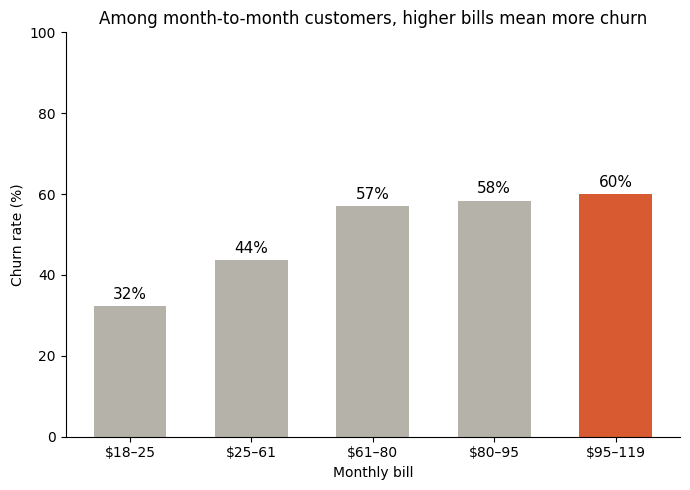

In [59]:
# Month-to-month customers only, so contract type is held constant
mtm = active[active['Contract'] == 'Month-to-Month']

churn_by_charge_mtm = mtm.groupby('Charge Band', observed=True)['Churn Value'].agg(['mean', 'count'])
churn_by_charge_mtm['mean'] = (churn_by_charge_mtm['mean'] * 100).round(1)
churn_by_charge_mtm.columns = ['Churn rate (%)', 'Customers']
churn_by_charge_mtm.index = ['$18–25', '$25–61', '$61–80', '$80–95', '$95–119']
churn_by_charge_mtm.index.name = 'Monthly bill'
display(churn_by_charge_mtm)

rates = churn_by_charge_mtm['Churn rate (%)']

# Grey for every band, highlight colour for the most expensive one
colours = []
for band in rates.index:
    if band == '$95–119':
        colours.append('#D85A30')
    else:
        colours.append('#B4B2A9')

fig, ax = plt.subplots(figsize=(7, 5))
bars = ax.bar(rates.index, rates.values, color=colours, width=0.6)
ax.bar_label(bars, fmt='%.0f%%', padding=3, fontsize=11)

ax.set_ylim(0, 100)
ax.set_xlabel('Monthly bill')
ax.set_ylabel('Churn rate (%)')
ax.set_title('Among month-to-month customers, higher bills mean more churn')
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.savefig('churn_by_charge_mtm.png', dpi=200, bbox_inches='tight')
plt.show()

In [60]:
print(pd.crosstab(active['Tenure Group'], active['Charge Band'],
                  values=active['Churn Value'], aggfunc='mean').round(3))

Charge Band   (18.249, 25.45]  (25.45, 60.81]  (60.81, 79.99]  (79.99, 94.8]  \
Tenure Group                                                                   
0-6                     0.547           0.743           0.867          0.845   
7-12                    0.087           0.244           0.350          0.639   
13-24                   0.046           0.219           0.307          0.456   
25-48                   0.022           0.113           0.199          0.309   
49-72                   0.015           0.066           0.047          0.084   

Charge Band   (94.8, 118.75]  
Tenure Group                  
0-6                    0.926  
7-12                   0.800  
13-24                  0.549  
25-48                  0.373  
49-72                  0.179  


Tenure Group
0-6      77.2
7-12     35.3
13-24    28.7
25-48    20.4
49-72     9.5
Name: Churn Value, dtype: float64

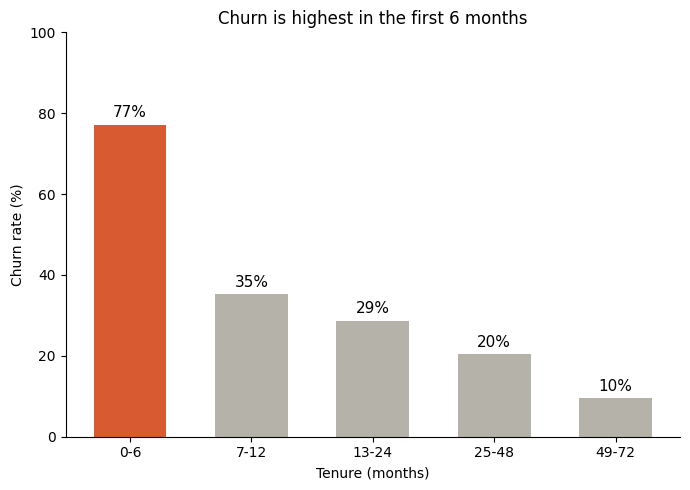

In [61]:
churn_by_tenure = (active.groupby('Tenure Group', observed=True)['Churn Value'].mean() * 100).round(1)
display(churn_by_tenure)

# Grey for every tenure group, highlight colour for the first 6 months
colours = []
for group in churn_by_tenure.index:
    if group == '0-6':
        colours.append('#D85A30')
    else:
        colours.append('#B4B2A9')

fig, ax = plt.subplots(figsize=(7, 5))
bars = ax.bar(churn_by_tenure.index.astype(str), churn_by_tenure.values, color=colours, width=0.6)
ax.bar_label(bars, fmt='%.0f%%', padding=3, fontsize=11)

ax.set_ylim(0, 100)
ax.set_xlabel('Tenure (months)')
ax.set_ylabel('Churn rate (%)')
ax.set_title('Churn is highest in the first 6 months')
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.savefig('churn_by_tenure.png', dpi=200, bbox_inches='tight')
plt.show()

We can see that churn rate decreases as tenure increases. The 0-6 month tenure group show the highest churn rate at ~78%.

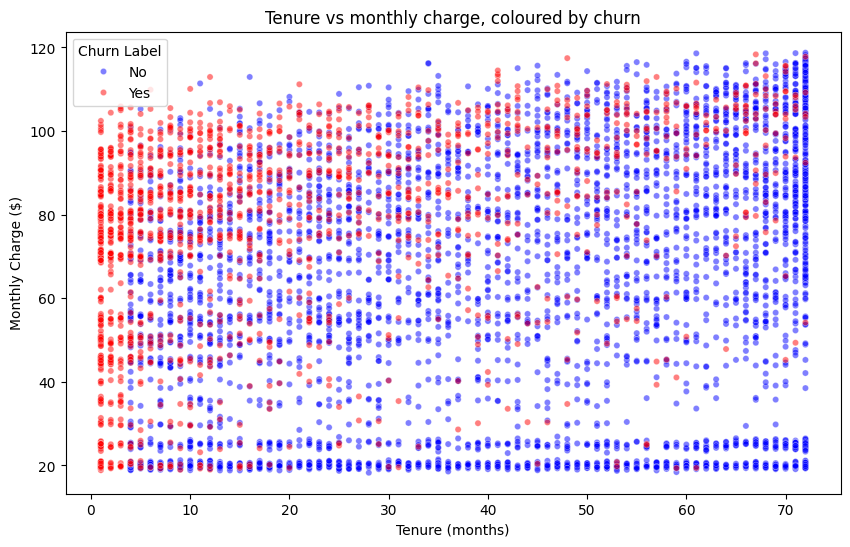

In [62]:
# Create a scatter plot of tenure and monthly charge, coloured by churn
plot_data = active.sort_values('Churn Label')   # draw churners last so they're not hidden

plt.figure(figsize=(10, 6))
sns.scatterplot(data=plot_data, x='Tenure in Months', y='Monthly Charge',
                hue='Churn Label', palette={'No': 'blue', 'Yes': 'red'},
                alpha=0.5, s=20)
plt.xlabel("Tenure (months)")
plt.ylabel("Monthly Charge ($)")
plt.title("Tenure vs monthly charge, coloured by churn")
plt.show()

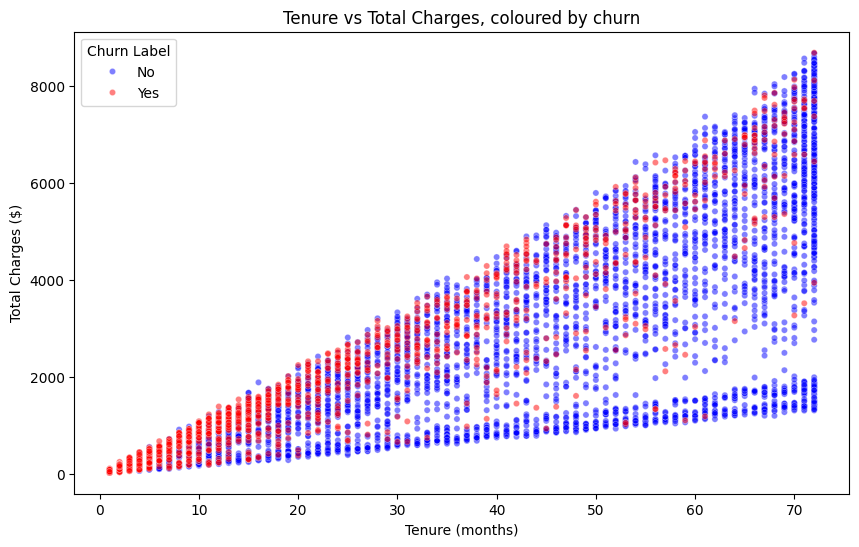

In [63]:
# Create a scatter plot of tenure and total charges, coloured by churn
plot_data = active.sort_values('Churn Label')   # draw churners last so they're not hidden

plt.figure(figsize=(10, 6))
sns.scatterplot(data=plot_data, x='Tenure in Months', y='Total Charges',
                hue='Churn Label', palette={'No': 'blue', 'Yes': 'red'},
                alpha=0.5, s=20)
plt.xlabel("Tenure (months)")
plt.ylabel("Total Charges ($)")
plt.title("Tenure vs Total Charges, coloured by churn")
plt.show()

## 3.5 Churn by contract type

Contract
Month-to-Month    51.7
One Year          10.9
Two Year           2.6
Name: Churn Value, dtype: float64

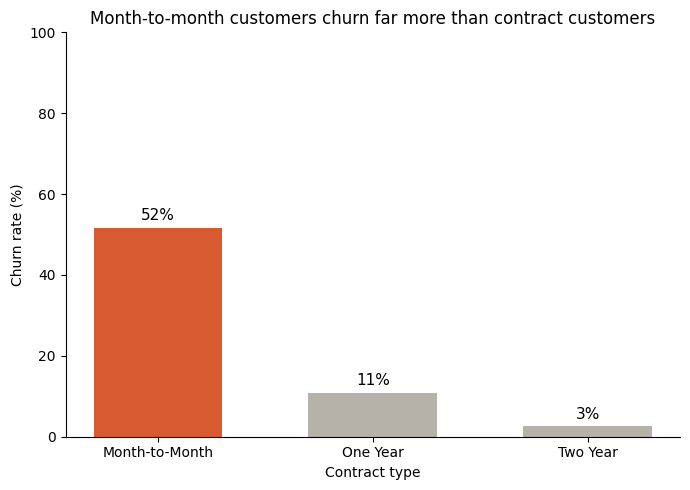

In [64]:
churn_by_contract = (active.groupby('Contract', observed=True)['Churn Value'].mean() * 100).round(1)
display(churn_by_contract)

# Grey for every contract type, highlight colour for month-to-month
colours = []
for contract in churn_by_contract.index:
    if contract == 'Month-to-Month':
        colours.append('#D85A30')
    else:
        colours.append('#B4B2A9')

fig, ax = plt.subplots(figsize=(7, 5))
bars = ax.bar(churn_by_contract.index, churn_by_contract.values, color=colours, width=0.6)
ax.bar_label(bars, fmt='%.0f%%', padding=3, fontsize=11)

ax.set_ylim(0, 100)
ax.set_xlabel('Contract type')
ax.set_ylabel('Churn rate (%)')
ax.set_title('Month-to-month customers churn far more than contract customers')
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.savefig('churn_by_contract.png', dpi=200, bbox_inches='tight')
plt.show()

## 3.6 Services: Premium Tech Support and Online Security

In [65]:
service_cols = ['Online Security', 'Online Backup', 'Device Protection Plan', 'Premium Tech Support', 'Streaming TV', 'Streaming Movies', 'Streaming Music', 'Unlimited Data']

for col in service_cols:
    print((active.groupby(col)['Churn Value'].mean() * 100).round(1), '\n')

Online Security
No     34.1
Yes    15.0
Name: Churn Value, dtype: float64 

Online Backup
No     31.9
Yes    22.0
Name: Churn Value, dtype: float64 

Device Protection Plan
No     31.5
Yes    22.8
Name: Churn Value, dtype: float64 

Premium Tech Support
No     34.0
Yes    15.5
Name: Churn Value, dtype: float64 

Streaming TV
No     26.8
Yes    30.6
Name: Churn Value, dtype: float64 

Streaming Movies
No     26.9
Yes    30.5
Name: Churn Value, dtype: float64 

Streaming Music
No     27.5
Yes    29.9
Name: Churn Value, dtype: float64 

Unlimited Data
No     17.7
Yes    33.2
Name: Churn Value, dtype: float64 



,Without,With,Difference
Service,,,
Online Security,34.1,15.0,-19.1
Premium Tech Support,34.0,15.5,-18.4
Online Backup,31.9,22.0,-9.9
Device Protection Plan,31.5,22.8,-8.7
Streaming Music,27.5,29.9,2.4
Streaming Movies,26.9,30.5,3.6
Streaming TV,26.8,30.6,3.8
Unlimited Data,17.7,33.2,15.5


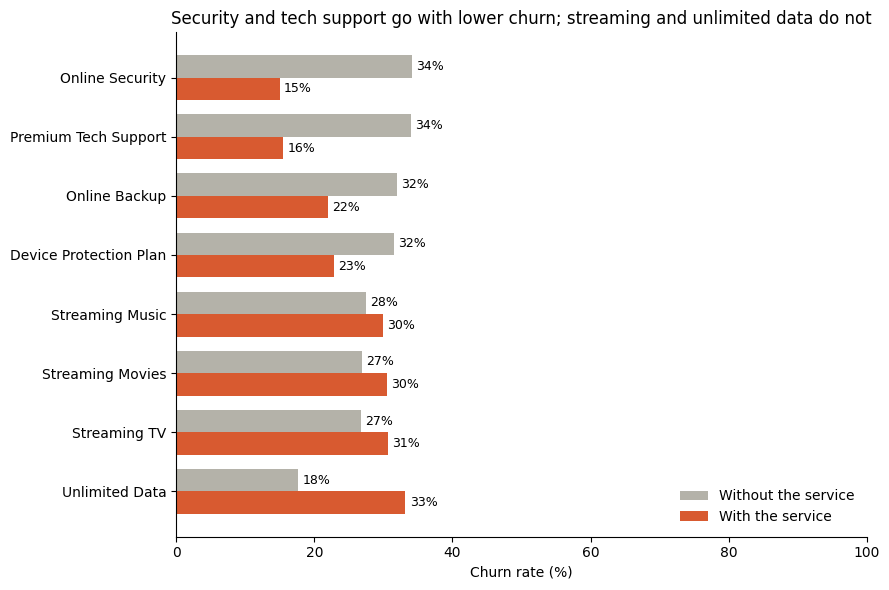

In [66]:
service_cols = ['Online Security', 'Online Backup', 'Device Protection Plan', 'Premium Tech Support',
                'Streaming TV', 'Streaming Movies', 'Streaming Music', 'Unlimited Data']

# One row per service: churn rate without it, with it, and the difference
rows = []
for col in service_cols:
    rates = active.groupby(col)['Churn Value'].mean() * 100
    rows.append({
        'Service':     col,
        'Without':     rates['No'],
        'With':        rates['Yes'],
        'Difference':  rates['Yes'] - rates['No'],
    })

service_churn = pd.DataFrame(rows).set_index('Service').round(1)

# Biggest drop in churn at the top
service_churn = service_churn.sort_values('Difference')
display(service_churn)

y = np.arange(len(service_churn))       # one position per service
bar_height = 0.38

fig, ax = plt.subplots(figsize=(9, 6))

bars_without = ax.barh(y - bar_height / 2, service_churn['Without'], height=bar_height,
                       color='#B4B2A9', label='Without the service')
bars_with = ax.barh(y + bar_height / 2, service_churn['With'], height=bar_height,
                    color='#D85A30', label='With the service')

ax.bar_label(bars_without, fmt='%.0f%%', padding=3, fontsize=9)
ax.bar_label(bars_with, fmt='%.0f%%', padding=3, fontsize=9)

ax.set_yticks(y)
ax.set_yticklabels(service_churn.index)
ax.invert_yaxis()                        # first row (biggest drop) at the top
ax.set_xlim(0, 100)
ax.set_xlabel('Churn rate (%)')
ax.set_title('Security and tech support go with lower churn; streaming and unlimited data do not')
ax.legend(frameon=False, loc='lower right')
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.savefig('churn_by_service.png', dpi=200, bbox_inches='tight')
plt.show()

Customers who pay for Premium Tech Support, online security and online backup have the lowest churn rates.

An alternative explanation: customers who sign up for these services may be the ones who were going to stay anyway, such as long-tenure customers on two-year contracts. To test this, we hold contract type constant and see if the gap survives.

In [67]:
merge_final_internet_services = active[active['Internet Service'] == 'Yes'].copy()

In [68]:
(pd.crosstab(merge_final_internet_services['Contract'], merge_final_internet_services['Premium Tech Support'],
             values=merge_final_internet_services['Churn Value'], aggfunc='mean') * 100).round(1)

Premium Tech Support,No,Yes
Contract,,
Month-to-Month,59.6,35.4
One Year,13.4,13.3
Two Year,3.8,3.4


In [69]:
pd.crosstab(merge_final_internet_services['Contract'], merge_final_internet_services['Premium Tech Support'])

Premium Tech Support,No,Yes
Contract,,
Month-to-Month,2264,582
One Year,612,563
Two Year,372,852


We repeat the same analysis for online security:

In [70]:
(pd.crosstab(merge_final_internet_services['Contract'], merge_final_internet_services['Online Security'],
             values=merge_final_internet_services['Churn Value'], aggfunc='mean') * 100).round(1)

Online Security,No,Yes
Contract,,
Month-to-Month,60.3,34.5
One Year,16.1,10.5
Two Year,4.8,2.8


In [71]:
pd.crosstab(merge_final_internet_services['Contract'], merge_final_internet_services['Online Security'])

Online Security,No,Yes
Contract,,
Month-to-Month,2228,618
One Year,602,573
Two Year,442,782


**Result:** the gap survives within month-to-month contracts, where most of the churn is (Tech Support 59.6% vs 35.4%; Online Security 60.3% vs 34.5%; each cell has 580+ customers). It mostly disappears on one- and two-year contracts, where churn is already low. Paying for these services therefore goes with lower churn.

## 3.7 Number of services (internet customers)

In [72]:
pd.crosstab(active['Phone Service'], active['Internet Service'])

Internet Service,No,Yes
Phone Service,,
No,0,644
Yes,1344,4601


In [73]:
# Check every column only contains Yes/No
for col in service_cols:
    print(col, active[col].unique())

# Count of services per customer (0–8)
merge_final_internet_services['Number of Services'] = (merge_final_internet_services[service_cols] == 'Yes').sum(axis=1)

# Churn rate by number of services
merge_final_internet_services.groupby('Number of Services').agg(
    churn_rate=('Churn Value', 'mean'),
    customers=('Customer ID', 'count')
)

Online Security ['No' 'Yes']
Online Backup ['No' 'Yes']
Device Protection Plan ['Yes' 'No']
Premium Tech Support ['No' 'Yes']
Streaming TV ['No' 'Yes']
Streaming Movies ['Yes' 'No']
Streaming Music ['No' 'Yes']
Unlimited Data ['No' 'Yes']


,churn_rate,customers
Number of Services,,
0,0.603175,63
1,0.591837,588
2,0.447682,755
3,0.395181,830
4,0.316471,850
5,0.285539,816
6,0.210287,661
7,0.113786,457
8,0.048889,225


In [74]:
(pd.crosstab(merge_final_internet_services['Number of Services'], merge_final_internet_services['Contract'],
             values=merge_final_internet_services['Churn Value'], aggfunc='mean') * 100).round(1)

Contract,Month-to-Month,One Year,Two Year
Number of Services,,,
0,63.3,0.0,NaN
1,65.7,10.0,0.0
2,54.9,5.2,0.0
3,55.5,8.1,3.1
4,52.3,9.7,3.9
5,48.4,16.6,3.7
6,46.8,16.5,5.4
7,22.0,22.5,3.7
8,50.0,13.8,2.1


In [75]:
pd.crosstab(merge_final_internet_services['Number of Services'], merge_final_internet_services['Contract'])

Contract,Month-to-Month,One Year,Two Year
Number of Services,,,
0,60,3,0
1,525,30,33
2,607,97,51
3,560,173,97
4,459,236,155
5,382,247,187
6,188,231,242
7,59,129,269
8,6,29,190


## 3.8 Churn by age group and Senior Citizen (Y/N)

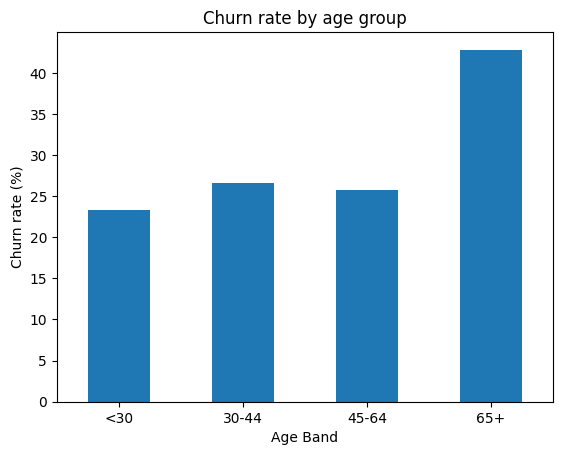

In [76]:
churn_by_age = active.groupby('Age Band', observed=True)['Churn Value'].mean() * 100

churn_by_age.plot.bar()
plt.ylabel('Churn rate (%)')
plt.title('Churn rate by age group')
plt.xticks(rotation=0)
plt.show()

In [77]:
(pd.crosstab(active['Age Band'], active['Tenure Group'],
             values=active['Churn Value'], aggfunc='mean') * 100).round(1)

Tenure Group,0-6,7-12,13-24,25-48,49-72
Age Band,,,,,
<30,71.6,21.6,22.0,15.0,8.6
30-44,76.2,36.7,27.8,14.5,8.6
45-64,77.2,33.0,24.0,17.4,7.7
65+,84.5,57.3,49.4,41.3,16.1


In [78]:
(pd.crosstab(active['Tenure Group'], active['Senior Citizen'],
             values=active['Churn Value'], aggfunc='mean') * 100).round(1)

Senior Citizen,No,Yes
Tenure Group,,
0-6,75.5,84.5
7-12,31.6,57.3
13-24,24.6,49.4
25-48,15.9,41.3
49-72,8.2,16.1


,Under 65,Senior (65+)
Tenure Group,,
0-6,75.5,84.5
7-12,31.6,57.3
13-24,24.6,49.4
25-48,15.9,41.3
49-72,8.2,16.1


,Under 65,Senior (65+)
Tenure Group,,
0-6,829,187
7-12,613,103
13-24,856,168
25-48,1313,281
49-72,1866,373


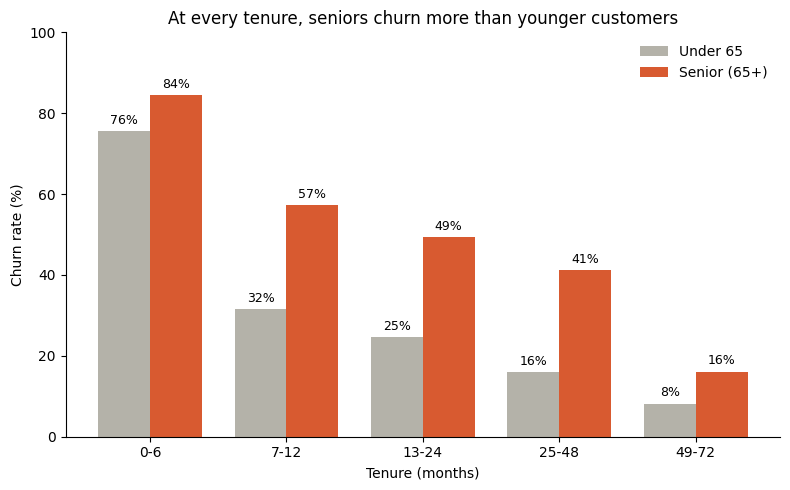

In [79]:
# Churn rate for under-65 vs seniors, within each tenure group
senior_by_tenure = (pd.crosstab(active['Tenure Group'], active['Senior Citizen'],
                                values=active['Churn Value'], aggfunc='mean') * 100).round(1)
senior_by_tenure.columns = ['Under 65', 'Senior (65+)']      # 'No' -> Under 65, 'Yes' -> Senior

# Counts, to check no group is below ~30 customers
senior_counts = pd.crosstab(active['Tenure Group'], active['Senior Citizen'])
senior_counts.columns = ['Under 65', 'Senior (65+)']

display(senior_by_tenure)
display(senior_counts)

tenure_labels = senior_by_tenure.index.astype(str)
x = np.arange(len(tenure_labels))      # one position per tenure group: 0, 1, 2, 3, 4
bar_width = 0.38

fig, ax = plt.subplots(figsize=(8, 5))

# Under-65 bars shifted left, senior bars shifted right, so each pair sits side by side
bars_under = ax.bar(x - bar_width / 2, senior_by_tenure['Under 65'], width=bar_width,
                    color='#B4B2A9', label='Under 65')
bars_senior = ax.bar(x + bar_width / 2, senior_by_tenure['Senior (65+)'], width=bar_width,
                     color='#D85A30', label='Senior (65+)')

ax.bar_label(bars_under, fmt='%.0f%%', padding=3, fontsize=9)
ax.bar_label(bars_senior, fmt='%.0f%%', padding=3, fontsize=9)

ax.set_xticks(x)
ax.set_xticklabels(tenure_labels)
ax.set_ylim(0, 100)
ax.set_xlabel('Tenure (months)')
ax.set_ylabel('Churn rate (%)')
ax.set_title('At every tenure, seniors churn more than younger customers')
ax.legend(frameon=False)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.savefig('churn_seniors_by_tenure.png', dpi=200, bbox_inches='tight')
plt.show()

In [80]:
active.columns

Index(['Customer ID', 'Quarter', 'Referred a Friend', 'Number of Referrals',
       'Tenure in Months', 'Offer', 'Phone Service',
       'Avg Monthly Long Distance Charges', 'Multiple Lines',
       'Internet Service', 'Internet Type', 'Avg Monthly GB Download',
       'Online Security', 'Online Backup', 'Device Protection Plan',
       'Premium Tech Support', 'Streaming TV', 'Streaming Movies',
       'Streaming Music', 'Unlimited Data', 'Contract', 'Paperless Billing',
       'Payment Method', 'Monthly Charge', 'Total Charges', 'Total Refunds',
       'Total Extra Data Charges', 'Total Long Distance Charges',
       'Total Revenue', 'Satisfaction Score', 'Customer Status', 'Churn Label',
       'Churn Value', 'Churn Score', 'CLTV', 'Churn Category', 'Churn Reason',
       'Country', 'State', 'City', 'Zip Code', 'Lat Long', 'Latitude',
       'Longitude', 'Gender', 'Age', 'Under 30', 'Senior Citizen', 'Married',
       'Dependents', 'Number of Dependents', 'Population', 'Tenure Group'

## 3.9 Location

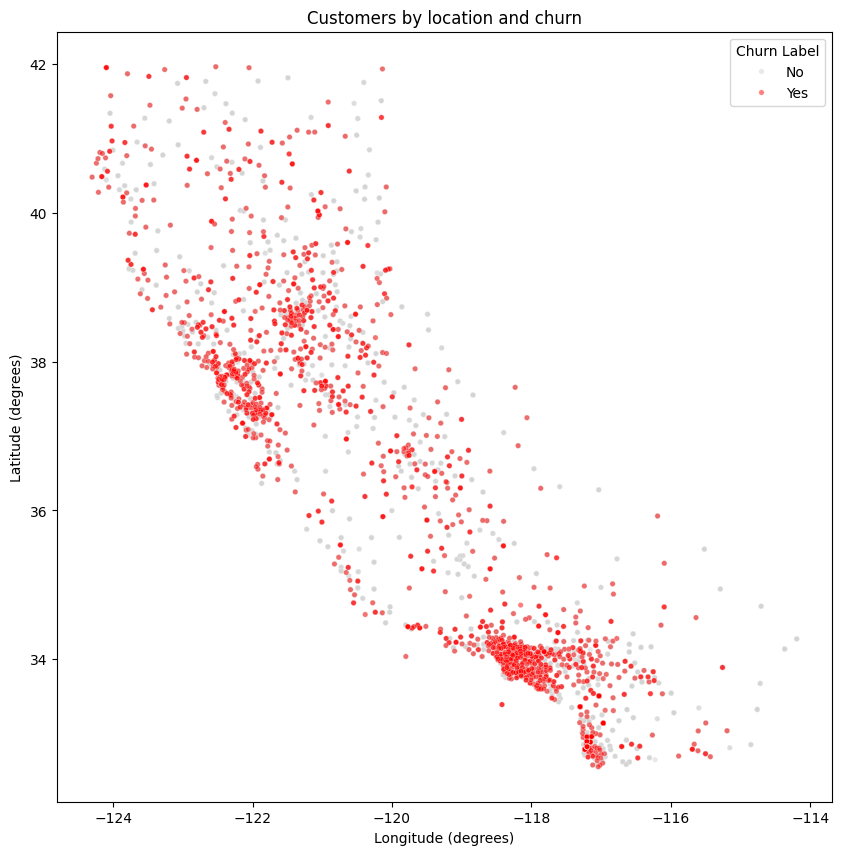

In [81]:
plot_data = active.sort_values('Churn Label')   # 'No' first, 'Yes' last, so churners drawn on top

plt.figure(figsize=(10, 10))
ax = sns.scatterplot(x='Longitude', y='Latitude', data=plot_data,
                     hue='Churn Label', palette={'No': 'lightgrey', 'Yes': 'red'},
                     alpha=0.5, s=15)
plt.xlabel('Longitude (degrees)')
plt.ylabel('Latitude (degrees)')
plt.title('Customers by location and churn')
plt.show()

## 3.10 Churn reasons

In [82]:
active['Churn Reason'].value_counts(normalize= True)

Churn Reason
Competitor had better devices                0.167469
Competitor made better offer                 0.166399
Attitude of support person                   0.117710
Don't know                                   0.069556
Competitor offered more data                 0.062600
Competitor offered higher download speeds    0.053505
Attitude of service provider                 0.050294
Price too high                               0.041734
Product dissatisfaction                      0.041199
Network reliability                          0.038523
Long distance charges                        0.034243
Service dissatisfaction                      0.033708
Moved                                        0.024612
Extra data charges                           0.020867
Limited range of services                    0.019797
Poor expertise of online support             0.016586
Lack of affordable download/upload speed     0.016051
Lack of self-service on Website              0.015516
Poor expertise 

In [83]:
competitor_offer = active[active['Churn Reason'] == 'Competitor made better offer'].copy()

In [84]:
competitor_offer['Offer'].value_counts()

Offer
None       174
Offer E     78
Offer C     21
Offer D     19
Offer B     13
Offer A      6
Name: count, dtype: int64

After discovering that senior citizens have much greater odds of churning, I'm trying to see what their churn reasons are compared to the baseline population. 

In [85]:
active[active['Senior Citizen'] == 'Yes']['Churn Reason'].value_counts(normalize= True)

Churn Reason
Competitor made better offer                 0.189076
Competitor had better devices                0.176471
Attitude of support person                   0.134454
Competitor offered more data                 0.056723
Don't know                                   0.054622
Price too high                               0.054622
Attitude of service provider                 0.052521
Product dissatisfaction                      0.048319
Network reliability                          0.037815
Limited range of services                    0.031513
Service dissatisfaction                      0.031513
Competitor offered higher download speeds    0.025210
Extra data charges                           0.025210
Long distance charges                        0.021008
Poor expertise of online support             0.021008
Moved                                        0.016807
Lack of affordable download/upload speed     0.016807
Deceased                                     0.004202
Poor expertise 

In [86]:
active[active['Senior Citizen'] == 'Yes']['Offer'].value_counts(normalize= True)

Offer
None       0.609712
Offer B    0.097122
Offer E    0.089928
Offer C    0.075540
Offer A    0.071942
Offer D    0.055755
Name: proportion, dtype: float64

In [87]:
active[active['Senior Citizen'] == 'No']['Offer'].value_counts(normalize= True)

Offer
None       0.533139
Offer B    0.130729
Offer D    0.098594
Offer E    0.096768
Offer A    0.080336
Offer C    0.060435
Name: proportion, dtype: float64

In [88]:
pd.crosstab(active['Offer'],
            [active['Tenure Group'], active['Senior Citizen']],
            values=active['Churn Value'], aggfunc='mean')

Tenure Group         0-6                7-12               13-24            \
Senior Citizen        No       Yes        No       Yes        No       Yes   
Offer                                                                        
None            0.722595  0.862385  0.340694  0.573529  0.273563  0.469027   
Offer A              NaN       NaN       NaN       NaN       NaN       NaN   
Offer B              NaN       NaN       NaN       NaN       NaN       NaN   
Offer C              NaN       NaN       NaN       NaN  0.137931  0.666667   
Offer D              NaN       NaN  0.256757  0.692308  0.224490  0.530612   
Offer E         0.793194  0.820513  0.324324  0.500000       NaN       NaN   

Tenure Group       25-48               49-72            
Senior Citizen        No       Yes        No       Yes  
Offer                                                   
None            0.166876  0.390805  0.083333  0.172897  
Offer A              NaN       NaN  0.072727  0.037500  
Offer B         0.116822  0.413793  0.087649  0.253165  
Offer C         0.168874  0.461538       NaN       NaN  
Offer D              NaN       NaN       NaN       NaN  
Offer E              NaN       NaN       NaN       NaN

Senior citizens' top reason for churning is that a competitor made a better offer. 19% of senior citizens mention this as opposed to 16% across the overall population. Yet, we can see that 61% are never given one. 

We can see that offer E is offered to the newest joiners (0-6 months), as they are high-risk churners. Perhaps, we should consider changing the offer strategy for senior citizens.

# 4. Feature preparation

- Training population: `active` (customers at the start of Q3, Joined excluded), 6,589 customers.
- Create engineered features, one-hot encode categories, build the feature matrix.

## 4.1 Create engineered features (Phone Lines, Referral Band, Internet Type blanks)

In [89]:
model_df = active.copy()

In [90]:
model_df['Internet Type'] = model_df['Internet Type'].fillna('None')

In [91]:
conditions = [
    (model_df['Phone Service'] == 'Yes') & (model_df['Multiple Lines'] == 'No'),
    (model_df['Phone Service'] == 'Yes') & (model_df['Multiple Lines'] == 'Yes'),
    (model_df['Phone Service'] == 'No')  & (model_df['Multiple Lines'] == 'No'),
]
choices = ['Single phone line', 'Multiple phone lines', 'No phone lines']

model_df['Phone service option'] = np.select(conditions, choices, default='Check')

model_df['Phone service option'].value_counts()

Phone service option
Single phone line       3019
Multiple phone lines    2926
No phone lines           644
Name: count, dtype: int64

In [92]:
model_df['Referral Band'] = pd.cut(active['Number of Referrals'],
                                bins=[-1, 0, 1, 4, 11],
                                labels=['0', '1', '2-4', '5+'])
model_df['Referral Band'].value_counts().sort_index()

Referral Band
0      3448
1      1071
2-4     709
5+     1361
Name: count, dtype: int64

## 4.2 Encode categorical columns and pick features

In [93]:
# 1. Text columns to one-hot encode (Internet Type blanks already filled as 'None')
cat_cols = ['Internet Type', 'Tenure Group', 'Phone service option', 'Referral Band',
            'Online Security', 'Online Backup', 'Device Protection Plan',
            'Premium Tech Support', 'Streaming TV', 'Streaming Movies',
            'Streaming Music', 'Unlimited Data', 'Contract', 'Paperless Billing',
            'Payment Method', 'Senior Citizen', 'Married', 'Dependents']

model_df = pd.get_dummies(model_df, columns=cat_cols, drop_first=True, dtype=int)

# 2. Number columns kept as numbers
num_cols = ['Avg Monthly GB Download', 'Monthly Charge']

# 3. Pick up every dummy column created from cat_cols (avoids typing names by hand)
dummy_cols = [c for c in model_df.columns
              if c.startswith(tuple(col + '_' for col in cat_cols))]

X = model_df[num_cols + dummy_cols]                                    # option B: tenure as bands
y = model_df['Churn Value']

X.columns

Index(['Avg Monthly GB Download', 'Monthly Charge', 'Internet Type_DSL',
       'Internet Type_Fiber Optic', 'Internet Type_None', 'Tenure Group_7-12',
       'Tenure Group_13-24', 'Tenure Group_25-48', 'Tenure Group_49-72',
       'Phone service option_No phone lines',
       'Phone service option_Single phone line', 'Referral Band_1',
       'Referral Band_2-4', 'Referral Band_5+', 'Online Security_Yes',
       'Online Backup_Yes', 'Device Protection Plan_Yes',
       'Premium Tech Support_Yes', 'Streaming TV_Yes', 'Streaming Movies_Yes',
       'Streaming Music_Yes', 'Unlimited Data_Yes', 'Contract_One Year',
       'Contract_Two Year', 'Paperless Billing_Yes',
       'Payment Method_Credit Card', 'Payment Method_Mailed Check',
       'Senior Citizen_Yes', 'Married_Yes', 'Dependents_Yes'],
      dtype='object')

In [94]:
print(X.shape)
print(X.dtypes.value_counts())
print(X.isna().sum().sum())
print(y.mean().round(3))

(6589, 30)
int64      29
float64     1
Name: count, dtype: int64
0
0.284


# 5. Modelling

Three logistic regression models, each removing features that turned out to be risky or misleading. Model 3 is the final model.

| Model | Features | Test AUC |
|---|---|---|
| 1 | All audited features, incl. Monthly Charge and Referral Band | 0.923 |
| 2 | Model 1 minus Referral Band | 0.901 |
| 3 (final) | Model 2 minus Monthly Charge | 0.899 |

## 5.1 Model 1: all audited features

### Train/test split and scaling

In [95]:
# Use test_train_split to create the training and test sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)


In [96]:
scaler = StandardScaler()

X_train = X_train.copy()
X_test = X_test.copy()

X_train[num_cols] = scaler.fit_transform(X_train[num_cols])   # learn average + spread from train, then scale train
X_test[num_cols]  = scaler.transform(X_test[num_cols])        # scale test using the TRAIN average + spread

### Fit and coefficients

In [97]:
# Create and fit the logistic regression model
model = LogisticRegression(solver='lbfgs', max_iter=1000).fit(X_train, y_train)

In [98]:
coefs = pd.DataFrame({'feature': X_train.columns,
                      'coefficient': model.coef_[0]})
    
coefs['odds_ratio'] = np.exp(coefs['coefficient'])
coefs.sort_values('coefficient', ascending=False).round(3)

,feature,coefficient,odds_ratio
1,Monthly Charge,1.720,5.584
9,Phone service option_No phone lines,1.275,3.580
11,Referral Band_1,1.169,3.218
27,Senior Citizen_Yes,0.678,1.971
26,Payment Method_Mailed Check,0.618,1.855
20,Streaming Music_Yes,0.285,1.330
28,Married_Yes,0.256,1.292
24,Paperless Billing_Yes,0.218,1.243
4,Internet Type_None,0.207,1.230
10,Phone service option_Single phone line,0.073,1.076


### Test set performance

In [99]:
# Create predictions of probability for churn status using test data
preds = model.predict_proba(X_test)

In [100]:
preds_df = pd.DataFrame(preds[:,1], columns = ['prob_churn'])

# Concatenate and print the two data frames for comparison
print(pd.concat([y_test.reset_index(drop = True), preds_df], axis = 1))

      Churn Value  prob_churn
0               0    0.573888
1               1    0.773133
2               0    0.021255
3               0    0.008328
4               1    0.388684
...           ...         ...
1313            0    0.003082
1314            0    0.062499
1315            1    0.490200
1316            0    0.008379
1317            1    0.900010

[1318 rows x 2 columns]


In [101]:
# Calculating the accuracy of the model's first iteration:
model.score(X_test, y_test)

0.8634294385432474

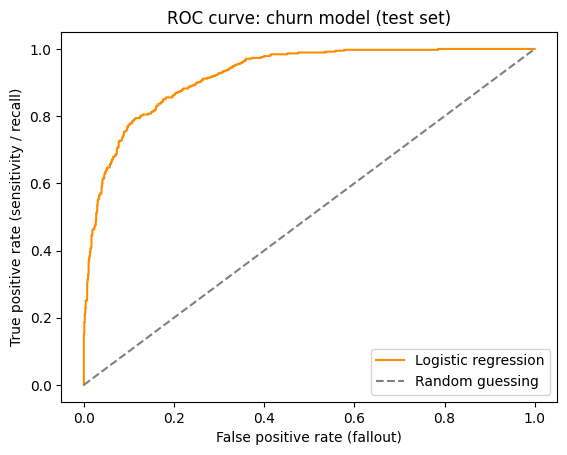

AUC: 0.923


In [102]:
# Plotting the ROC chart
fallout, sensitivity, thresholds = roc_curve(y_test, preds_df['prob_churn'])
plt.plot(fallout, sensitivity, color = 'darkorange', label='Logistic regression')

plt.plot([0, 1], [0, 1], linestyle='--', color='grey', label='Random guessing')
plt.xlabel('False positive rate (fallout)')
plt.ylabel('True positive rate (sensitivity / recall)')
plt.title('ROC curve: churn model (test set)')
plt.legend()
plt.show()

print('AUC:', roc_auc_score(y_test, preds_df['prob_churn']).round(3))

In [103]:
# Reassign churn status based on the threshold
preds_df['churn_status'] = preds_df['prob_churn'].apply(lambda x: 1 if x > 0.5 else 0)

# Print the row counts for each loan status
print(preds_df['churn_status'].value_counts())

# Print the classification report
target_names = ['Stayed', 'Churned']
print(classification_report(y_test, preds_df['churn_status'], target_names=target_names))

churn_status
0    984
1    334
Name: count, dtype: int64
              precision    recall  f1-score   support

      Stayed       0.89      0.93      0.91       944
     Churned       0.79      0.71      0.75       374

    accuracy                           0.86      1318
   macro avg       0.84      0.82      0.83      1318
weighted avg       0.86      0.86      0.86      1318



In [104]:
confusion_matrix(y_test, model.predict(X_test))

array([[874,  70],
       [110, 264]])

### Overfitting check: train vs test AUC

In [105]:
# Create predictions of probability for churn status using training data
preds_training = model.predict_proba(X_train)

In [106]:
preds_df_training = pd.DataFrame(preds_training[:,1], columns = ['prob_churn'])
print('AUC_training:', roc_auc_score(y_train, preds_df_training['prob_churn']).round(3))

AUC_training: 0.926


Train AUC 0.926 vs test AUC 0.923, so no sign of overfitting.

## 5.2 Model 2: drop Referral Band

**Referral Band: drop.** In model 1, one referral had about 3x the odds of churning while 2+ referrals had lower odds: a pattern with no business explanation. The referral count is measured at the end of Q3, so it may include referrals made after 1 July (possible leakage). Dropping it costs AUC 0.923 → 0.901.

In [107]:
dummy_cols_2 = [c for c in model_df.columns
                if c.startswith(tuple(col + '_' for col in cat_cols))
                and not c.startswith('Referral Band_')]

X2 = model_df[num_cols + dummy_cols_2]                                    # option B: tenure as bands
print(X2.columns)

Index(['Avg Monthly GB Download', 'Monthly Charge', 'Internet Type_DSL',
       'Internet Type_Fiber Optic', 'Internet Type_None', 'Tenure Group_7-12',
       'Tenure Group_13-24', 'Tenure Group_25-48', 'Tenure Group_49-72',
       'Phone service option_No phone lines',
       'Phone service option_Single phone line', 'Online Security_Yes',
       'Online Backup_Yes', 'Device Protection Plan_Yes',
       'Premium Tech Support_Yes', 'Streaming TV_Yes', 'Streaming Movies_Yes',
       'Streaming Music_Yes', 'Unlimited Data_Yes', 'Contract_One Year',
       'Contract_Two Year', 'Paperless Billing_Yes',
       'Payment Method_Credit Card', 'Payment Method_Mailed Check',
       'Senior Citizen_Yes', 'Married_Yes', 'Dependents_Yes'],
      dtype='object')


In [108]:
# Use test_train_split to create the training and test sets
X2_train, X2_test, y2_train, y2_test = train_test_split(X2, y, test_size=0.2, random_state=42, stratify=y)

In [109]:
X2_train = X2_train.copy()
X2_test = X2_test.copy()

X2_train[num_cols] = scaler.fit_transform(X2_train[num_cols])   # learn average + spread from train, then scale train
X2_test[num_cols]  = scaler.transform(X2_test[num_cols])       # scale test using the TRAIN average + spread

In [110]:
# Create and fit the 2nd logistic regression model
model2 = LogisticRegression(solver='lbfgs', max_iter=1000).fit(X2_train, y2_train)

In [111]:
coefs2 = pd.DataFrame({'feature': X2_train.columns,
                      'coefficient': model2.coef_[0]})
    
coefs2['odds_ratio'] = np.exp(coefs2['coefficient'])
coefs2.sort_values('coefficient', ascending=False).round(3)

,feature,coefficient,odds_ratio
1,Monthly Charge,1.911,6.759
9,Phone service option_No phone lines,1.511,4.530
24,Senior Citizen_Yes,0.652,1.919
23,Payment Method_Mailed Check,0.596,1.815
4,Internet Type_None,0.339,1.404
17,Streaming Music_Yes,0.266,1.305
25,Married_Yes,0.256,1.292
21,Paperless Billing_Yes,0.205,1.228
10,Phone service option_Single phone line,0.096,1.100
0,Avg Monthly GB Download,-0.096,0.908


In [112]:
# Create predictions of probability for churn status using test data
preds2 = model2.predict_proba(X2_test)

In [113]:
preds_df_2 = pd.DataFrame(preds2[:,1], columns = ['prob_churn'])

# Concatenate and print the two data frames for comparison
print(pd.concat([y2_test.reset_index(drop = True), preds_df_2], axis = 1))

      Churn Value  prob_churn
0               0    0.569153
1               1    0.769307
2               0    0.109914
3               0    0.007623
4               1    0.394722
...           ...         ...
1313            0    0.005655
1314            0    0.282026
1315            1    0.517572
1316            0    0.002589
1317            1    0.905311

[1318 rows x 2 columns]


In [114]:
print('AUC2:', roc_auc_score(y2_test, preds_df_2['prob_churn']).round(3))

AUC2: 0.901


**Check on the 'No phone lines' odds ratio (4.53 in model 2):** raw churn is similar for customers with and without phone service (26.4% vs 28.6%), so the large odds ratio is not a real phone effect. It comes from holding Monthly Charge constant: a no-phone customer on the same bill as a phone customer is paying more for less.

In [115]:
active.groupby('Phone Service')['Churn Value'].agg('mean')

Phone Service
No     0.263975
Yes    0.285786
Name: Churn Value, dtype: float64

## 5.3 Why Monthly Charge was dropped

Predicting monthly charge from the service columns to see if monthly charge is largely explained by them (R^2 of 0.95+ would indicate that). This is evidence I can use to later justify removing monthly charge from the feature set.

In [116]:
cat_cols_linear = ['Internet Type', 'Phone service option',
                   'Online Security', 'Online Backup', 'Device Protection Plan',
                   'Premium Tech Support', 'Streaming TV', 'Streaming Movies',
                   'Streaming Music', 'Unlimited Data']

service_dummy_cols = [c for c in model_df.columns
                if c.startswith(tuple(col + '_' for col in cat_cols_linear))]

X_lin = model_df[service_dummy_cols]
y_lin = model_df['Monthly Charge']

print(len(service_dummy_cols))   # sanity check: should be 13

13


In [117]:
X4_train, X4_test, y4_train, y4_test = train_test_split(X_lin, y_lin, test_size=0.3, random_state=42)
lm = LinearRegression()
lm.fit(X4_train, y4_train)

LinearRegression()

In [118]:
predictions_monthly_charge = lm.predict(X4_test)
coef_services = pd.DataFrame(lm.coef_, X_lin.columns, columns=["Model coefficient"]).round(2)
print('Intercept:', round(lm.intercept_, 2))
coef_services

Intercept: 52.92


,Model coefficient
Internet Type_DSL,-2.01
Internet Type_Fiber Optic,22.39
Internet Type_None,-27.82
Phone service option_No phone lines,-26.21
Phone service option_Single phone line,-5.21
Online Security_Yes,4.60
Online Backup_Yes,4.85
Device Protection Plan_Yes,5.01
Premium Tech Support_Yes,4.62
Streaming TV_Yes,10.03


In [119]:
r2 = r2_score(y4_test, predictions_monthly_charge)
print(r2)

0.9926063860466001


**Monthly Charge: drop as a feature** (still used as the revenue figure in Section 7). The 13 service dummies rebuild the bill almost exactly (R² = 0.99), so Monthly Charge and the services compete for the same signal. With it included, coefficients flip in ways that don't make sense (e.g. No phone lines 4.53 → 0.86, Fiber 0.32 → 1.26). Dropping it costs only AUC 0.901 → 0.899. The price insight is kept through EDA instead (Section 3.4).

## 5.4 Model 3 (final): drop Referral Band and Monthly Charge

In [120]:
num_cols_2 = ['Avg Monthly GB Download']
X3 = model_df[num_cols_2 + dummy_cols_2]   

In [121]:
# Use test_train_split to create the training and test sets
X3_train, X3_test, y3_train, y3_test = train_test_split(X3, y, test_size=0.2, random_state=42, stratify=y)

X3_train = X3_train.copy()
X3_test = X3_test.copy()

scaler3 = StandardScaler()

X3_train[num_cols_2] = scaler3.fit_transform(X3_train[num_cols_2])   # learn average + spread from train, then scale train
X3_test[num_cols_2]  = scaler3.transform(X3_test[num_cols_2])        # scale test using the TRAIN average + spread

# Create and fit the logistic regression model
model3 = LogisticRegression(solver='lbfgs', max_iter=1000).fit(X3_train, y3_train)


coefs3 = pd.DataFrame({'feature': X3_train.columns,
                      'coefficient': model3.coef_[0]})
    
coefs3['odds_ratio'] = np.exp(coefs3['coefficient'])
coefs3.sort_values('coefficient', ascending=False).round(3)

,feature,coefficient,odds_ratio
23,Senior Citizen_Yes,0.685,1.985
22,Payment Method_Mailed Check,0.561,1.753
14,Streaming TV_Yes,0.284,1.328
24,Married_Yes,0.267,1.306
16,Streaming Music_Yes,0.250,1.285
2,Internet Type_Fiber Optic,0.227,1.255
20,Paperless Billing_Yes,0.213,1.237
15,Streaming Movies_Yes,0.139,1.149
12,Device Protection Plan_Yes,-0.012,0.988
0,Avg Monthly GB Download,-0.090,0.914


# 6. Final model evaluation (model 3)

## 6.1 Test AUC and ROC curve

In [122]:
preds_3 = model3.predict_proba(X3_test)
preds_df_3 = pd.DataFrame(preds_3[:,1], columns = ['prob_churn'])

print('AUC:', roc_auc_score(y3_test, preds_df_3['prob_churn']).round(3))

AUC: 0.899


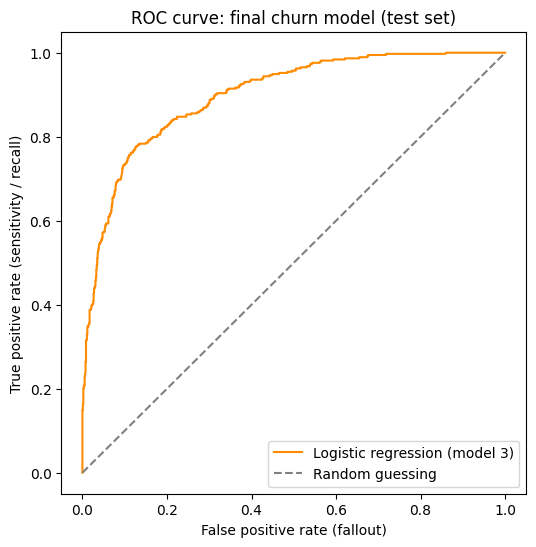

In [123]:
# Plotting the ROC chart for the final model
fallout_3, sensitivity_3, thresholds_3 = roc_curve(y3_test, preds_df_3['prob_churn'])

plt.figure(figsize=(6, 6))
plt.plot(fallout_3, sensitivity_3, color='darkorange', label='Logistic regression (model 3)')
plt.plot([0, 1], [0, 1], linestyle='--', color='grey', label='Random guessing')
plt.xlabel('False positive rate (fallout)')
plt.ylabel('True positive rate (sensitivity / recall)')
plt.title('ROC curve: final churn model (test set)')
plt.legend()
plt.savefig('roc_curve_model3.png', dpi=200, bbox_inches='tight')
plt.show()

## 6.2 Overfitting check: train vs test AUC

In [124]:
# Score the customers the model learned from, then compare with the unseen test customers
preds_3_train = model3.predict_proba(X3_train)

auc_train_3 = roc_auc_score(y3_train, preds_3_train[:, 1])
auc_test_3 = roc_auc_score(y3_test, preds_df_3['prob_churn'])

print(f'Train AUC: {auc_train_3:.3f}')
print(f'Test AUC:  {auc_test_3:.3f}')
print(f'Gap:       {auc_train_3 - auc_test_3:.3f}')

Train AUC: 0.907
Test AUC:  0.899
Gap:       0.009


# 7. Business translation

- **Expected revenue saved** = chance of leaving × 30% save rate × monthly charge × horizon (months).
- **Expected net** = expected revenue saved − \$100 credit.
- Rank customers by expected net, not by chance of leaving, and contact everyone with a positive expected net (capacity cap: 1,000).
- **Horizon:** 6 months is the main case. 85% of targets are month-to-month and can leave at any time, so 12 months is optimistic; 3 months assumes every saved customer leaves straight after the quarter. 3 and 12 months are shown as sensitivity cases.

## 7.1 Score current customers (Stayed + Joined = 5,174)

Preparing the Q4 dataset to which we will apply the trained logistic regression model to.

In [125]:
q4_df = merge_final[merge_final['Customer Status'] != 'Churned'].copy()

In [126]:
q4_df['Tenure Group'] = pd.cut(q4_df['Tenure in Months'],
                                bins=[0, 6, 12, 24, 48, 72],
                                labels=['0-6', '7-12', '13-24', '25-48', '49-72'])

In [127]:
q4_df['Internet Type'] = q4_df['Internet Type'].fillna('None')

In [128]:
conditions_2 = [
    (q4_df['Phone Service'] == 'Yes') & (q4_df['Multiple Lines'] == 'No'),
    (q4_df['Phone Service'] == 'Yes') & (q4_df['Multiple Lines'] == 'Yes'),
    (q4_df['Phone Service'] == 'No')  & (q4_df['Multiple Lines'] == 'No'),
]

q4_df['Phone service option'] = np.select(conditions_2, choices, default='Check')

q4_df['Phone service option'].value_counts()

Phone service option
Single phone line       2541
Multiple phone lines    2121
No phone lines           512
Name: count, dtype: int64

In [129]:
# 1. Text columns to one-hot encode (Internet Type blanks already filled as 'None')
cat_cols_q4 = ['Internet Type', 'Tenure Group', 'Phone service option',
            'Online Security', 'Online Backup', 'Device Protection Plan',
            'Premium Tech Support', 'Streaming TV', 'Streaming Movies',
            'Streaming Music', 'Unlimited Data', 'Contract', 'Paperless Billing',
            'Payment Method', 'Senior Citizen', 'Married', 'Dependents']

q4_df = pd.get_dummies(q4_df, columns=cat_cols_q4, drop_first=True, dtype=int)

X_q4 = q4_df[num_cols_2 + dummy_cols_2]                                   

In [130]:
X_q4 = X_q4.copy()
X_q4[num_cols_2]  = scaler3.transform(X_q4[num_cols_2])        

In [131]:
preds_q4 = model3.predict_proba(X_q4)
q4_df['prob_churn'] = preds_q4[:, 1]

In [132]:
q4_df.sort_values(by='prob_churn', ascending=False)

,Customer ID,Quarter,Referred a Friend,Number of Referrals,Tenure in Months,Offer,Phone Service,Avg Monthly Long Distance Charges,Multiple Lines,Internet Service,Avg Monthly GB Download,Monthly Charge,Total Charges,Total Refunds,Total Extra Data Charges,Total Long Distance Charges,Total Revenue,Satisfaction Score,Customer Status,Churn Label,Churn Value,Churn Score,CLTV,Churn Category,Churn Reason,Country,State,City,Zip Code,Lat Long,Latitude,Longitude,Gender,Age,Under 30,Number of Dependents,Population,Internet Type_DSL,Internet Type_Fiber Optic,Internet Type_None,Tenure Group_7-12,Tenure Group_13-24,Tenure Group_25-48,Tenure Group_49-72,Phone service option_No phone lines,Phone service option_Single phone line,Online Security_Yes,Online Backup_Yes,Device Protection Plan_Yes,Premium Tech Support_Yes,Streaming TV_Yes,Streaming Movies_Yes,Streaming Music_Yes,Unlimited Data_Yes,Contract_One Year,Contract_Two Year,Paperless Billing_Yes,Payment Method_Credit Card,Payment Method_Mailed Check,Senior Citizen_Yes,Married_Yes,Dependents_Yes,prob_churn
958,3295-YVUSR,Q3,No,0,2,NaN,Yes,15.19,Yes,Yes,30,72.60,154.30,0.00,0,30.38,184.68,3,Joined,No,0,47,5098,NaN,NaN,United States,California,Glendale,91202,"34.167926, -118.267539",34.167926,-118.267539,Male,73,No,0,"21,990",0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,1,0,1,1,0,0,0.966541
3638,7398-SKNQZ,Q3,Yes,5,3,NaN,Yes,2.97,Yes,Yes,7,94.90,273.20,0.00,0,8.91,282.11,5,Joined,No,0,58,2330,NaN,NaN,United States,California,Downey,90241,"33.940884, -118.128628",33.940884,-118.128628,Female,51,No,0,"40,152",0,1,0,0,0,0,0,0,0,0,0,0,0,1,1,1,1,0,0,0,0,0,0,1,0,0.950045
2968,5760-IFJOZ,Q3,No,0,3,NaN,Yes,47.50,Yes,Yes,22,107.95,313.60,0.00,0,142.50,456.10,4,Joined,No,0,77,3449,NaN,NaN,United States,California,Richgrove,93261,"35.809921, -119.127437",35.809921,-119.127437,Male,57,No,0,"2,956",0,1,0,0,0,0,0,0,0,0,1,1,0,1,1,1,1,0,0,0,0,1,0,0,0,0.949886
1125,6229-LSCKB,Q3,No,0,6,Offer E,Yes,48.32,No,Yes,11,79.70,497.60,0.00,0,289.92,787.52,5,Stayed,No,0,44,2893,NaN,NaN,United States,California,Encino,91436,"34.152875, -118.486056",34.152875,-118.486056,Male,69,No,0,"13,129",0,1,0,0,0,0,0,0,1,0,0,0,0,1,0,0,1,0,0,1,0,0,1,0,0,0.949510
4150,4927-WWOOZ,Q3,No,0,2,NaN,Yes,49.41,Yes,Yes,20,91.45,171.45,0.00,10,98.82,280.27,5,Joined,No,0,32,4889,NaN,NaN,United States,California,Pacific Grove,93950,"36.618337, -121.926417",36.618337,-121.926417,Male,39,No,0,"15,449",0,1,0,0,0,0,0,0,0,0,0,1,0,1,0,0,0,0,0,1,0,0,0,1,0,0.943874
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5877,3507-GASNP,Q3,No,0,60,Offer B,Yes,16.59,No,No,0,19.95,1189.90,0.00,0,995.40,2185.30,3,Stayed,No,0,74,5316,NaN,NaN,United States,California,North Hollywood,91602,"34.15136, -118.364786",34.151360,-118.364786,Male,49,No,2,"16,996",0,0,1,0,0,0,1,0,1,0,0,0,0,0,0,0,0,0,1,0,1,0,0,0,1,0.000872
3868,8957-THMOA,Q3,No,0,50,NaN,Yes,18.95,No,No,0,20.15,970.85,0.00,0,947.50,1918.35,3,Stayed,No,0,27,4263,NaN,NaN,United States,California,Big Bear City,92314,"34.278967, -116.773825",34.278967,-116.773825,Female,40,No,3,"9,899",0,0,1,0,0,0,1,0,1,0,0,0,0,0,0,0,0,0,1,0,1,0,0,0,1,0.000872
2931,2804-ETQDK,Q3,No,0,66,NaN,Yes,20.63,No,No,0,20.55,1357.10,17.14,0,1361.58,2701.54,4,Stayed,No,0,74,4101,NaN,NaN,United States,California,Ventura,93004,"34.278697, -119.167798",34.278697,-119.167798,Male,57,No,2,"27,381",0,0,1,0,0,0,1,0,1,0,0,0,0,0,0,0,0,0,1,0,1,0,0,0,1,0.000872
4154,0784-ZQJZX,Q3,No,0,72,NaN,Yes,31.93,No,No,0,19.90,1529.65,0.00,0,2298.96,3828.61,4,Stayed,No,0,72,5730,NaN,NaN,United States,California,Spreckels,93962,"36.624641, -121.647195",36.624641,-121.647195,Male,22,Yes,1,407,0,0,1,0,0,0,1,0,1,0,0,0,0,0,0,0,0,0,1,0,1,0,0,0,1,0.000872


In [133]:
q4_df['prob_churn'].describe()

count    5174.000000
mean        0.192717
std         0.239699
min         0.000872
25%         0.015698
50%         0.073395
75%         0.308266
max         0.966541
Name: prob_churn, dtype: float64

## 7.2 Main case: expected net value at a 6-month horizon

In [134]:
horizon_3 = 3
horizon_6 = 6
horizon_12 = 12
prob_credit_works = 0.3
credit = 100
q4_df['Exp_rev_saves'] = (q4_df['prob_churn'] * prob_credit_works * q4_df['Monthly Charge'] * horizon_6) 
q4_df['Potential_net'] = q4_df['Exp_rev_saves'] - credit
optimal_number_customers_to_contact = q4_df[q4_df['Potential_net'] > 0]['Potential_net'].count()
thousand_customers_contact = 1000
total_cost_to_contact = optimal_number_customers_to_contact * credit
total_expected_revenue_saved = q4_df[q4_df['Potential_net'] > 0]['Exp_rev_saves'].sum()
campaign_potential_net = q4_df[q4_df['Potential_net'] > 0]['Potential_net'].sum()
q4_df_sorted = q4_df.sort_values(by='Exp_rev_saves', ascending=False).head(1000)
net_1000_customers = q4_df_sorted['Potential_net'].head(1000).sum()

In [135]:
print(f"The optimal number of customers to contact is: {optimal_number_customers_to_contact}")
print(f"The total cost to contact these customers is: ${total_cost_to_contact:,.2f}")
print(f"The total expected revenue saved over a {horizon_6}-month horizon is: ${total_expected_revenue_saved:,.2f}")
print(f"The total net from the campaign is: ${campaign_potential_net:,.2f}")
print(f"The total net from contacting {thousand_customers_contact:,} customers is: ${net_1000_customers:,.2f}")

The optimal number of customers to contact is: 253
The total cost to contact these customers is: $25,300.00
The total expected revenue saved over a 6-month horizon is: $30,410.50
The total net from the campaign is: $5,110.50
The total net from contacting 1,000 customers is: $-19,798.98


## 7.3 Horizon sensitivity: 3 / 6 / 12 months

In [136]:
def campaign_summary(horizon, n_max=1000):
    # Net value per customer for this horizon (not saved into q4_df, so nothing gets overwritten)
    exp_saved = q4_df['prob_churn'] * prob_credit_works * q4_df['Monthly Charge'] * horizon
    net = exp_saved - credit

    worth_it = net > 0                                   # True/False for each customer

    return {
        'Horizon (months)':       horizon,
        'Optimal contacts':       worth_it.sum(),        # number of Trues
        'Expected revenue saved': exp_saved[worth_it].sum(),
        'Cost':                   worth_it.sum() * credit,
        'Net (optimal)':          net[worth_it].sum(),
        'Net (contact 1,000)':    net.sort_values(ascending=False).head(n_max).sum(),
    }

In [137]:
horizons = [3, 6, 12]

rows = []
for h in horizons:
    rows.append(campaign_summary(h))

strategy_table = pd.DataFrame(rows)
strategy_table.round(0)

,Horizon (months),Optimal contacts,Expected revenue saved,Cost,Net (optimal),"Net (contact 1,000)"
0,3,0,0.0,0,0.0,-59899.0
1,6,253,30410.0,25300,5110.0,-19799.0
2,12,883,149479.0,88300,61179.0,60402.0


At 3 months no customer is worth contacting: even the highest-value customer saves less than the \$100 credit. At 6 months, 253 customers are worth contacting (net \$5,110). At 12 months, 883 (net \$61,179). The 1,000-customer cap never binds. Contacting all 1,000 would lose money at 3 and 6 months.

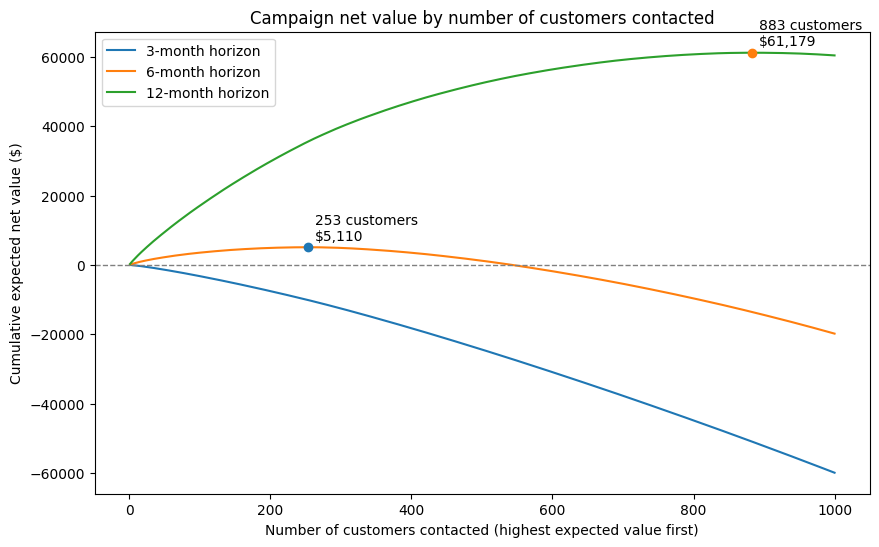

In [138]:
horizons = [horizon_3, horizon_6, horizon_12]

plt.figure(figsize=(10, 6))

for h in horizons:
    # Expected net value per customer for this horizon
    net = q4_df['prob_churn'] * prob_credit_works * q4_df['Monthly Charge'] * h - credit

    # Best customers first, keep the top 1,000, renumber 0..999
    net_sorted = net.sort_values(ascending=False).head(thousand_customers_contact).reset_index(drop=True)

    # Running total: net from contacting the top 1, top 2, ... top 1,000
    cum_net = net_sorted.cumsum()

    x = range(1, len(cum_net) + 1)          # 1 to 1,000 customers contacted
    plt.plot(x, cum_net, label=f'{h}-month horizon')

    # Mark the peak (the optimal number to contact), if the campaign ever makes money
    if cum_net.max() > 0:
        best_n = cum_net.idxmax() + 1
        plt.scatter(best_n, cum_net.max(), zorder=3)
        plt.annotate(f'{best_n} customers\n${cum_net.max():,.0f}',
                     (best_n, cum_net.max()), textcoords='offset points', xytext=(5, 5))

plt.axhline(0, color='grey', linestyle='--', linewidth=1)   # break-even line
plt.xlabel('Number of customers contacted (highest expected value first)')
plt.ylabel('Cumulative expected net value ($)')
plt.title('Campaign net value by number of customers contacted')
plt.legend()
plt.savefig('campaign_net_by_contacts.png', dpi=200, bbox_inches='tight')
plt.show()

## 7.4 Who are the targets?

In [139]:
len(q4_df_sorted)

1000

In [140]:
q4_df_sorted[(q4_df_sorted['Contract_One Year'] == 0) & (q4_df_sorted['Contract_Two Year'] == 0)]['Churn Label'].count()

np.int64(852)

852 / 1000 of top 1000 at-risk customers are on month-to-month contracts.

## 7.5 Target profile vs all current customers

In [141]:
# Target group: everyone worth calling at the 6-month horizon
targets = q4_df[q4_df['Potential_net'] > 0]
print('Target group size:', len(targets))        # should be 253
print('All current customers:', len(q4_df))      # should be 5,174


def driver_profile(df):
    # Month-to-month = neither contract dummy is switched on
    month_to_month = (df['Contract_One Year'] == 0) & (df['Contract_Two Year'] == 0)

    # Tenure 0-6 = the reference band, so all four tenure dummies are 0
    tenure_0_6 = ((df['Tenure Group_7-12'] == 0) &
                  (df['Tenure Group_13-24'] == 0) &
                  (df['Tenure Group_25-48'] == 0) &
                  (df['Tenure Group_49-72'] == 0))

    return {
        'Month-to-month contract': month_to_month.mean() * 100,
        'Tenure 0-6 months':       tenure_0_6.mean() * 100,
        'Senior citizen':          (df['Senior Citizen_Yes'] == 1).mean() * 100,
        'Pays by mailed check':    (df['Payment Method_Mailed Check'] == 1).mean() * 100,
        'Has Online Security':     (df['Online Security_Yes'] == 1).mean() * 100,
    }


driver_table = pd.DataFrame({
    'All current customers': driver_profile(q4_df),
    'Target group':          driver_profile(targets),
}).round(1)

driver_table['Difference (pts)'] = driver_table['Target group'] - driver_table['All current customers']
display(driver_table)

# Average bill is in $, not %, so it is shown separately rather than on the chart
print(f"Average monthly bill, all current customers: ${q4_df['Monthly Charge'].mean():.2f}")
print(f"Average monthly bill, target group:          ${targets['Monthly Charge'].mean():.2f}")

Target group size: 253
All current customers: 5174


,All current customers,Target group,Difference (pts)
Month-to-month contract,37.8,96.8,59.0
Tenure 0-6 months,13.3,51.0,37.7
Senior citizen,12.9,22.9,10.0
Pays by mailed check,4.7,4.0,-0.7
Has Online Security,33.3,16.6,-16.7


Average monthly bill, all current customers: $61.27
Average monthly bill, target group:          $88.94


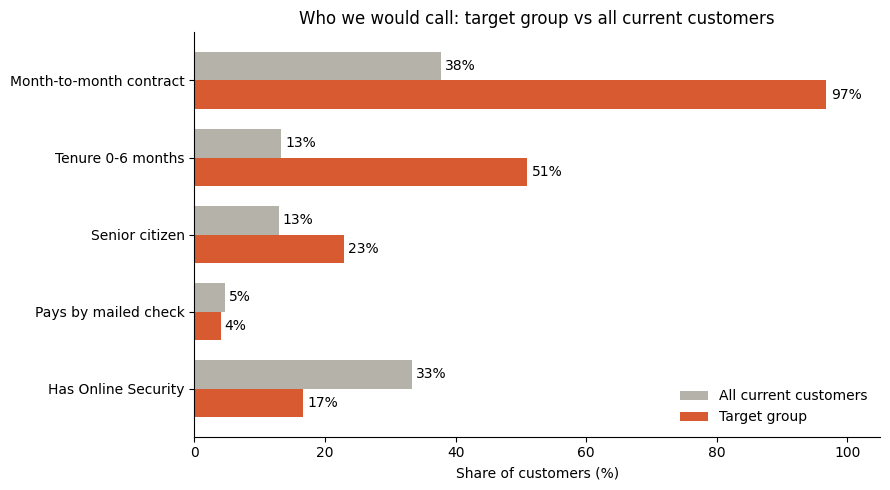

In [142]:
plot_table = driver_table[['All current customers', 'Target group']]

fig, ax = plt.subplots(figsize=(9, 5))

plot_table.plot.barh(ax=ax, color=['#B4B2A9', '#D85A30'], width=0.75)

# Put a % label at the end of every bar
for bars in ax.containers:
    ax.bar_label(bars, fmt='%.0f%%', padding=3, fontsize=10)

ax.invert_yaxis()                               # first driver at the top
ax.set_xlim(0, 105)
ax.set_xlabel('Share of customers (%)')
ax.set_ylabel('')
ax.set_title('Who we would call: target group vs all current customers')
ax.legend(loc='lower right', frameon=False)

# Lighter frame so the bars stand out
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.savefig('target_profile_vs_all.png', dpi=200, bbox_inches='tight')
plt.show()